<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/14_IoT_IIoT_Attack_Detection/QBoost_VQC_PegasosQSVC_SmartCityIDS_Caivano2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QBoost, VQC and Pegasos QSVC for smart-city IoT intrusion detection: Caivano et al. (2023) step by step

This notebook re-implements, runs and checks the experiment of

> Danilo Caivano, Mirko De Vincentiis, Anibrata Pal and Azzurra Ragone, "Securing Smart Cities: Unraveling Quantum as a Service",
> *Proceedings of the 2nd International Workshop on Quantum Programming for Software Engineering (QP4SE '23)*, San Francisco, December 4, 2023,
> ACM. DOI 10.1145/3617570.3617865

The paper proposes a "Quantum as a Service" (QaaS) architecture for a smart-city security operations centre: IoT traffic goes into a
core application, which calls quantum classifiers on a quantum cloud (a D-Wave annealer for **QBoost**, IBM Qiskit simulators for the
**Variational Quantum Classifier (VQC)** and the **Pegasos quantum SVM (PegasosQSVC)**) and shows detected incidents on a dashboard.
The only experiment that can be re-run is the comparison of the three classifiers on the MQTTset IoT intrusion dataset
(accuracy, precision, recall, F1 for 2, 4, 6 and 8 PCA components, Figure 5; training and prediction times, Table 1). The paper publishes no code.

**What the notebook does.**
1. Downloads the *reduced* MQTTset (330,926 MQTT packets, attack : legitimate = 50 : 50) from the dataset's public Kaggle bundle, extracting only the one CSV
   that is needed (7.6 MB of a 922 MB archive).
2. Applies the paper's cleaning (drop 6 categorical columns and 12 constant columns, leaving 15 features; legitimate = -1, every attack = +1;
   min-max scaling; PCA; 70 : 30 split) with every transform fitted on the training split only.
3. Implements **QBoost** (AdaBoost pool of 35 depth-3 trees, QUBO with lambda = 0.5) and solves the QUBO with a **simulated-annealing sampler written
   here** (3000 reads), because the D-Wave Leap hybrid solver of the paper needs a paid cloud account.
4. Trains **PegasosQSVC** (`FidelityQuantumKernel`, `z_feature_map` reps 2, C = 1000, 100 steps) and **VQC** (`zz_feature_map` reps 1, `real_amplitudes` reps 3,
   COBYLA 30 iterations, cross entropy) in Qiskit, exactly with the hyper-parameters the paper lists, on a small sample (the paper's runs took up to 30 hours).
5. Trains classical baselines (random forest, RBF SVM, plain AdaBoost) on identical inputs, redraws Figure 5 and Table 1 next to the paper's numbers,
   and states a verdict for every checkable claim.

**How to run it.** Open in Colab (badge above), choose a **CPU** runtime and use *Runtime -> Run all*. The first cell installs pinned Qiskit
packages; if Colab asks you to restart the session, do so and run all cells again. `FAST_MODE = True` (2 and 4 qubits, 150 training packets for the quantum models) takes
a few minutes; `FAST_MODE = False` runs 2, 4, 6 and 8 qubits with larger samples and several seeds and takes more than two hours on a CPU (the committed outputs are from the `FAST_MODE = True` run; see the configuration cell).
The data are public; no token is needed (see Section 1 for the fallbacks).

**What you get at the end.** Per-model, per-qubit-count metrics next to the paper's Figure 5, confusion matrices, the circuits that were actually executed,
the timing comparison of Table 1, and an honest list of which claims reproduce and which do not.

## The paper in one page

**Problem.** Smart-city IoT networks (smart-home MQTT sensors in the experiment) are attacked by denial of service, flooding, brute force, malformed packets and slow-connection
attacks. A security operations centre needs a classifier that labels each packet "attack" or "legitimate". The paper asks whether quantum classifiers accessed as a cloud service can do this.

**Decision.** Binary: legitimate (-1) against attack (+1, the five attack families merged).

**Methods compared.**
* **QBoost** (D-Wave Leap hybrid solver, Advantage_system5.3): a strong classifier is a subset of a pool of weak classifiers; choosing the subset is a quadratic unconstrained binary optimisation (QUBO)
  problem solved by quantum annealing. Hyper-parameters: 35 weak classifiers, tree depth 3, lambda = 0.5, 3000 reads, auto-scale on, 10 spin-reversal transforms.
* **VQC** (IBM Qiskit, local simulator): `ZZFeatureMap(reps=1)` + `RealAmplitudes(reps=3)`, COBYLA(maxiter=30), cross-entropy loss, one qubit per feature.
* **PegasosQSVC** (IBM Qiskit, local simulator): `FidelityQuantumKernel` with `ZFeatureMap(reps=2)`, C = 1000, 100 Pegasos steps.

**Data.** MQTTset (Vaccari et al., Sensors 2020), reduced version "with 330936 rows and 34 data variables"; 33 features + target with six labels (legitimate, DoS, malformed, bruteforce, slowite, flood).

**Preprocessing.** Remove the 6 categorical features and the 12 features that are constant, leaving 15; legitimate -> -1, rest -> 1; `MinMaxScaler`; PCA to 2, 4, 6 or 8 components; 70 : 30 train-test split.

**Claims that can be checked.**
* Figure 5 (bar charts of accuracy, precision, recall, F1 per model for n = 2, 4, 6, 8) and the text around it: QBoost is best in quality at every n; the gap is large at n = 2 and shrinks for larger n;
  QBoost does not improve with more features, VQC and PegasosQSVC are said to improve; with 14 features QBoost and PegasosQSVC gain only 2.4 % and 0 %.
* Table 1 (training and prediction time): PegasosQSVC trains fastest, QBoost predicts fastest, VQC trains slowest, PegasosQSVC predicts very slowly.
* Not checkable here: the dashboard (Figure 3), the architecture (Figure 1), the D-Wave hardware itself, the absolute wall-clock times on a 32-core server.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | MQTTset reduced, 330,936 rows, 34 columns | Same file from the Kaggle bundle `cnrieiit/mqttset` (`Data/FINAL_CSV/mqttdataset_reduced.csv`): **330,926 rows**, 34 columns (10 rows fewer than the paper states; shown in Section 1) |
| Cleaning | drop 6 categorical and 12 constant columns -> 15 features; legitimate -1, attacks +1; no balancing needed | Identical (the file is exactly 50 : 50). Duplicate rows are **kept**, as in the paper (209,499 of the 330,926 rows duplicate an earlier row; see the leakage check in Section 4) |
| Scaling and PCA | `MinMaxScaler`, PCA(n) | Same, but **fitted on the training split only** (`# CHOICE`); one PCA with 15 components is fitted and the first n columns are used, so the n = 2, 4, 6, 8 inputs are nested |
| Split | 70 : 30, no seed given | Stratified on the six original labels, `random_state = SEED` |
| Angle scaling for the Qiskit models | not mentioned; PCA scores are fed in directly | PCA scores are min-max scaled to [0, pi] for VQC and PegasosQSVC (repository convention, `# CHOICE`); an ablation with the raw PCA scores is run in Section 9 |
| QBoost weak classifiers | "35 weak classifiers, tree depth 3" | `AdaBoostClassifier(DecisionTreeClassifier(max_depth=3), n_estimators=35)`; its trees are the pool (the construction of D-Wave's open-source QBoost example) (`# CHOICE`) |
| QBoost objective | QUBO, lambda = 0.5 | Neven et al.'s objective: weak outputs scaled by 1/35, squared loss summed over the training samples, + lambda per selected classifier (`# CHOICE`: not normalised by the sample count) |
| QUBO solver | D-Wave Leap hybrid solver, 3000 reads, auto-scale, 10 spin-reversal transforms | **Simulated annealing** in numpy, 3000 reads, geometric temperature schedule (`# CHOICE`); auto-scale and spin-reversal transforms are QPU-hardware options with no classical analogue. Validated against exact enumeration on a 14-variable instance |
| VQC | ZZFeatureMap reps 1, RealAmplitudes reps 3, COBYLA(30), cross entropy | Identical; Qiskit's default exact sampler, parity interpretation of the bit-string |
| PegasosQSVC | FidelityQuantumKernel, ZFeatureMap reps 2, C = 1000, 100 steps | Identical |
| Training size for the quantum models | all training rows, about 231.6k (VQC took 3.9 to 30.6 hours) | **a few hundred packets** (`N_TRAIN_Q`), a stratified random sample of the training split; QBoost and the classical baselines are run both on the same sample and on the full training split |
| Test size | all test rows, about 99.3k | quantum models: stratified sample of `N_TEST_Q` test rows; QBoost and baselines: also on the full test split |
| Metrics | accuracy, precision, recall, F1; recall equals accuracy in Figure 5, so **weighted** averages | accuracy and weighted precision / recall / F1 (`sklearn`, `average="weighted"`) |
| Seeds | not stated | `SEED = 42`; several seeds where cheap |
| Hardware | 32-core AMD Threadripper, 64 GB, D-Wave Leap Europe | one laptop CPU or a Colab CPU runtime; times are therefore only comparable in order, not in size |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever Qiskit is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
_missing = [m for m in ("qiskit", "qiskit_machine_learning", "pylatexenc") if importlib.util.find_spec(m) is None]
if IN_COLAB or _missing:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" pylatexenc
    print("Qiskit installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("Qiskit and qiskit-machine-learning already present; skipping pip install.")

Qiskit and qiskit-machine-learning already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = True            # True: class demo (2 and 4 qubits, small samples), about 10-15 min on a CPU. False: 2, 4, 6, 8 qubits, larger samples, 3 seeds;
                            # the full path takes more than 2 hours on a shared laptop CPU (measured pieces: baselines 16 min, QBoost 14 min, PegasosQSVC 31 min, VQC over 40 min)
SEED      = 42              # every random number generator is seeded from this
DATA_DIR  = "mqttset_data"  # downloaded data are cached here (a scratch folder, never committed)
LOCAL_CSV = ""              # optional: path of a manually downloaded mqttdataset_reduced.csv (skips the download)
IBM_TOKEN = ""              # optional; the paper's IBM models run on simulators only, so this notebook never needs it
TEST_SIZE = 0.30            # the paper's 70 : 30 split

if FAST_MODE:
    QUBIT_COUNTS = [2, 4]
    N_TRAIN_Q, N_TEST_Q = 120, 100          # training / test packets for the Qiskit models and the like-for-like QBoost and baseline runs
    N_TRAIN_QB = 20_000                     # QBoost "large" arm (paper: all, about 231.6k)
    SEEDS = [SEED]                          # seeds for the cheap models (classical, QBoost)
    Q_SEEDS = [SEED, SEED + 1]              # seeds for PegasosQSVC and VQC (PegasosQSVC with 100 steps is very seed-dependent)
    SA_READS, SA_SWEEPS = 300, 150          # simulated-annealing reads / sweeps in FAST mode (paper: 3000 reads)
    VQC_MAXITER, PEG_STEPS = 30, 100        # the paper's values
    ABLATION_QUBITS = [2]                   # qubit counts for the raw-PCA (no [0, pi] scaling) ablation
    SVC_CAP = 3000                          # rows used to train the RBF-SVM baseline in its 'full' arm
else:
    QUBIT_COUNTS = [2, 4, 6, 8]             # the paper's four settings
    N_TRAIN_Q, N_TEST_Q = 200, 200
    N_TRAIN_QB = None                       # None = the whole training split (231,648 rows), as in the paper
    SEEDS = [SEED, SEED + 1, SEED + 2]
    Q_SEEDS = [SEED, SEED + 1]
    SA_READS, SA_SWEEPS = 3000, 200         # reads = paper's 3000
    VQC_MAXITER, PEG_STEPS = 30, 100
    ABLATION_QUBITS = [2]
    SVC_CAP = 10_000
ABL_SEEDS = Q_SEEDS[:1] if FAST_MODE else Q_SEEDS      # seeds used in the raw-PCA ablation
WEAK_CLASSIFIERS, TREE_DEPTH, LAMBDA = 35, 3, 0.5   # QBoost hyper-parameters from the paper
PEG_C = 1000                                        # PegasosQSVC regularisation from the paper
print(f"FAST_MODE={FAST_MODE}  qubits={QUBIT_COUNTS}  quantum train/test={N_TRAIN_Q}/{N_TEST_Q}  QBoost large-arm train={N_TRAIN_QB or 'all'}")

FAST_MODE=True  qubits=[2, 4]  quantum train/test=120/100  QBoost large-arm train=20000


In [3]:
import os, io, time, math, random, itertools, warnings, zipfile
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import requests
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay

import qiskit, qiskit_machine_learning
from qiskit.circuit.library import zz_feature_map, z_feature_map, real_amplitudes
from qiskit.quantum_info import Statevector
from qiskit_machine_learning.algorithms import PegasosQSVC, VQC
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals

warnings.filterwarnings("ignore")
random.seed(SEED)
np.random.seed(SEED)
algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| scikit-learn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | scikit-learn 1.9.1 | numpy 2.5.4 | pandas 3.0.6


## 1. The data: MQTTset (reduced version)

MQTTset (Vaccari, Chiola, Aiello, Mongelli, Cambiaso, *Sensors* 20(22), 2020) was captured on a simulated smart-home network: eight IoT sensors
(temperature, light, humidity, motion, CO-gas, smoke, fan, door lock) publish to an Eclipse Mosquitto MQTT broker. The authors then ran five attacks against the
broker: **DoS** (the "malariaDoS" capture), **flood** (MQTT publish flood), **SlowITe**, **malformed data** and **brute-force authentication**. Every packet is described by 33 `tshark`
fields (TCP and MQTT header fields) plus the label `target`.

The dataset is public on Kaggle (`cnrieiit/mqttset`, licence CC BY-NC-SA 4.0) as a 922 MB zip bundle that also holds the raw captures. The paper used the *reduced* file,
in which the legitimate traffic was cut to the size of the attack traffic (50 : 50). The cell below reads the zip's directory over HTTP range requests and extracts only
`Data/FINAL_CSV/mqttdataset_reduced.csv` (7.6 MB compressed); the file is cached in `DATA_DIR`. If the download is blocked, download the file by hand (Kaggle web page, no
code needed) and put its path in `LOCAL_CSV`, or upload it in Colab.

In [4]:
KAGGLE_ZIP_URL = "https://www.kaggle.com/api/v1/datasets/download/cnrieiit/mqttset"   # public dataset, anonymous download
MEMBER = "Data/FINAL_CSV/mqttdataset_reduced.csv"

class _HTTPFile(io.RawIOBase):
    """Read-only, seekable file object over HTTP range requests (lets zipfile read one member of a remote zip)."""
    def __init__(self, url):
        self.url, self.pos = url, 0
        h = requests.get(url, headers={"Range": "bytes=0-0"}, timeout=60)
        h.raise_for_status()
        self.size = int(h.headers["content-range"].split("/")[1])
    def seekable(self): return True
    def readable(self): return True
    def tell(self): return self.pos
    def seek(self, off, whence=0):
        self.pos = off if whence == 0 else (self.pos + off if whence == 1 else self.size + off)
        return self.pos
    def readinto(self, b):
        n = len(b)
        if n == 0 or self.pos >= self.size:
            return 0
        end = min(self.pos + n, self.size) - 1
        d = requests.get(self.url, headers={"Range": f"bytes={self.pos}-{end}"}, timeout=120).content
        b[:len(d)] = d
        self.pos += len(d)
        return len(d)

def get_mqttset_reduced():
    """Return the path of mqttdataset_reduced.csv (LOCAL_CSV, cache, or a range-request extraction from the Kaggle bundle)."""
    if LOCAL_CSV and os.path.exists(LOCAL_CSV):
        return LOCAL_CSV
    target = os.path.join(DATA_DIR, "mqttdataset_reduced.csv")
    if os.path.exists(target) and os.path.getsize(target) > 50_000_000:
        return target
    try:
        r = requests.get(KAGGLE_ZIP_URL, stream=True, timeout=60, allow_redirects=True)   # follows the redirect to a signed storage URL
        signed_url = r.url
        r.close()
        with zipfile.ZipFile(io.BufferedReader(_HTTPFile(signed_url), buffer_size=1 << 20)) as z:
            with z.open(MEMBER) as src, open(target, "wb") as dst:
                dst.write(src.read())
        return target
    except Exception as e:
        raise RuntimeError("Could not download MQTTset. Download 'mqttdataset_reduced.csv' from https://www.kaggle.com/datasets/cnrieiit/mqttset "
                           "(folder Data/FINAL_CSV) and set LOCAL_CSV to its path. Original error: " + repr(e))

t0 = time.perf_counter()
CSV_PATH = get_mqttset_reduced()
df = pd.read_csv(CSV_PATH, low_memory=False)
print(f"{CSV_PATH}: {os.path.getsize(CSV_PATH)/1e6:.1f} MB, loaded in {time.perf_counter()-t0:.1f} s")
print("shape:", df.shape, "(the paper says 330936 rows and 34 columns)")
df["target"] = df["target"].astype(str)
print(df["target"].value_counts())

mqttset_data\mqttdataset_reduced.csv: 59.4 MB, loaded in 5.1 s
shape: (330926, 34) (the paper says 330936 rows and 34 columns)
target
legitimate    165463
dos           130223
bruteforce     14501
malformed      10924
slowite         9202
flood            613
Name: count, dtype: int64


## 2. Cleaning and labels, as in the paper

The paper removes the six categorical columns (re-encoding them, e.g. one-hot encoding the address, would add many features and hence many qubits), removes the 12 columns that have
the same value in every row, and ends with 15 features. It then maps legitimate to -1 and every attack family to +1. We follow this and *check* every number the paper states
(6 categorical, 12 constant, 15 remaining, no NaN or infinity, balanced classes).

In [5]:
feature_cols = [c for c in df.columns if c != "target"]
categorical = [c for c in feature_cols if not pd.api.types.is_numeric_dtype(df[c])]
constant = [c for c in feature_cols if c not in categorical and df[c].nunique(dropna=False) == 1]
kept = [c for c in feature_cols if c not in categorical and c not in constant]
print(f"categorical columns removed ({len(categorical)}): {categorical}")
print(f"constant columns removed ({len(constant)}): {constant}")
print(f"features kept ({len(kept)}): {kept}")
assert (len(categorical), len(constant), len(kept)) == (6, 12, 15), "differs from the paper's 6 / 12 / 15"
X_all = df[kept].to_numpy(dtype=float)
print("NaN:", int(np.isnan(X_all).sum()), "| inf:", int(np.isinf(X_all).sum()))
family = df["target"].to_numpy(dtype=object)                  # six original labels
y_all = np.where(family == "legitimate", -1, 1)               # legitimate -> -1, every attack -> +1 (the paper's labels)
print("binary label counts (-1 legitimate / +1 attack):", dict(zip(*np.unique(y_all, return_counts=True))))

categorical columns removed (6): ['tcp.flags', 'mqtt.conack.flags', 'mqtt.conflags', 'mqtt.hdrflags', 'mqtt.msg', 'mqtt.protoname']
constant columns removed (12): ['mqtt.conack.flags.reserved', 'mqtt.conack.flags.sp', 'mqtt.conflag.qos', 'mqtt.conflag.reserved', 'mqtt.conflag.retain', 'mqtt.conflag.willflag', 'mqtt.sub.qos', 'mqtt.suback.qos', 'mqtt.willmsg', 'mqtt.willmsg_len', 'mqtt.willtopic', 'mqtt.willtopic_len']
features kept (15): ['tcp.time_delta', 'tcp.len', 'mqtt.conack.val', 'mqtt.conflag.cleansess', 'mqtt.conflag.passwd', 'mqtt.conflag.uname', 'mqtt.dupflag', 'mqtt.kalive', 'mqtt.len', 'mqtt.msgid', 'mqtt.msgtype', 'mqtt.proto_len', 'mqtt.qos', 'mqtt.retain', 'mqtt.ver']
NaN: 0 | inf: 0


binary label counts (-1 legitimate / +1 attack): {np.int64(-1): np.int64(165463), np.int64(1): np.int64(165463)}


## 3. Splitting and preprocessing (every transform fitted on the training split only)

The paper applies `MinMaxScaler`, then PCA, then a 70 : 30 split; fitting the scaler and the PCA on all rows would let the test rows influence the transforms. Here the split comes
first (stratified on the six original labels), then `MinMaxScaler` and one 15-component PCA are fitted on the training rows and applied to both splits. The inputs for n = 2, 4, 6, 8
qubits are the first n principal components. For the two Qiskit models the scores are then min-max scaled to [0, pi] (fitted on the training rows, test values clipped), so that they can be
used as rotation angles; the paper does not say whether it did this, and Section 9 runs an ablation without it.

Training the Qiskit models on all 231 thousand rows is out of reach on a laptop (the paper's own VQC runs took up to 30 hours on a 32-core server), so a **stratified random sample**
of `N_TRAIN_Q` training rows and `N_TEST_Q` test rows is drawn once (same rows for every model, so the comparison is like for like).

In [6]:
idx_all = np.arange(len(df))
idx_tr, idx_te = train_test_split(idx_all, test_size=TEST_SIZE, stratify=family, random_state=SEED)
Xtr_raw, Xte_raw, ytr, yte = X_all[idx_tr], X_all[idx_te], y_all[idx_tr], y_all[idx_te]
ftr, fte = family[idx_tr], family[idx_te]
print("train split:", Xtr_raw.shape, "| test split:", Xte_raw.shape, "(paper: about 231.6k / 99.3k)")

scaler01 = MinMaxScaler().fit(Xtr_raw)                                   # fitted on training rows only
N_PCA = 15
pca = PCA(n_components=N_PCA, random_state=SEED).fit(scaler01.transform(Xtr_raw))
Ptr = pca.transform(scaler01.transform(Xtr_raw))                         # PCA scores, training split
Pte = pca.transform(scaler01.transform(Xte_raw))                         # PCA scores, test split
print("explained variance ratio of the first 8 components:", np.round(pca.explained_variance_ratio_[:8], 3),
      "| cumulative first 2/4/8:", np.round(np.cumsum(pca.explained_variance_ratio_)[[1, 3, 7]], 3))

def stratified_sample(n, labels, seed):
    """Indices (into the arrays) of a stratified random sample of size n."""
    if n is None or n >= len(labels):
        return np.arange(len(labels))
    keep, _ = train_test_split(np.arange(len(labels)), train_size=n, stratify=labels, random_state=seed)
    return np.sort(keep)

sub_tr = stratified_sample(N_TRAIN_Q, ftr, SEED)       # quantum-size training sample
sub_te = stratified_sample(N_TEST_Q, fte, SEED)        # quantum-size test sample
print(f"quantum-size samples: train {len(sub_tr)}, test {len(sub_te)}; attack share train {np.mean(ytr[sub_tr] == 1):.2f}, test {np.mean(yte[sub_te] == 1):.2f}")

def angle_scaler(n):
    """MinMaxScaler to [0, pi] fitted on the training split's first n PCA scores (CHOICE: repository convention)."""
    return MinMaxScaler((0, np.pi)).fit(Ptr[:, :n])

def make_inputs(n, scaled=True):
    """Quantum-size train/test inputs for n qubits: [0, pi] angles (default) or the raw PCA scores."""
    if not scaled:
        return Ptr[sub_tr, :n], np.clip(Pte[sub_te, :n], Ptr[:, :n].min(0), Ptr[:, :n].max(0))
    sc = angle_scaler(n)
    return sc.transform(Ptr[sub_tr, :n]), np.clip(sc.transform(Pte[sub_te, :n]), 0, np.pi)

train split: (231648, 15) | test split: (99278, 15) (paper: about 231.6k / 99.3k)


explained variance ratio of the first 8 components: [0.602 0.12  0.101 0.093 0.042 0.016 0.013 0.006] | cumulative first 2/4/8: [0.721 0.916 0.993]


quantum-size samples: train 120, test 100; attack share train 0.50, test 0.50


## Dataset Exploration and Visualisation

Everything below uses the real MQTTset packets: their shape, columns and original labels, the class distribution, and a 2-D picture of real training packets coloured by their true attack
family. The scatter plots show the first two PCA components (fitted on the training split), then the same two coordinates scaled to [0, pi], which is exactly the input of the 2-qubit models.

dataset shape (rows, columns): (330926, 34)
all 33 feature names + target: ['tcp.flags', 'tcp.time_delta', 'tcp.len', 'mqtt.conack.flags', 'mqtt.conack.flags.reserved', 'mqtt.conack.flags.sp', 'mqtt.conack.val', 'mqtt.conflag.cleansess', 'mqtt.conflag.passwd', 'mqtt.conflag.qos', 'mqtt.conflag.reserved', 'mqtt.conflag.retain', 'mqtt.conflag.uname', 'mqtt.conflag.willflag', 'mqtt.conflags', 'mqtt.dupflag', 'mqtt.hdrflags', 'mqtt.kalive', 'mqtt.len', 'mqtt.msg', 'mqtt.msgid', 'mqtt.msgtype', 'mqtt.proto_len', 'mqtt.protoname', 'mqtt.qos', 'mqtt.retain', 'mqtt.sub.qos', 'mqtt.suback.qos', 'mqtt.ver', 'mqtt.willmsg', 'mqtt.willmsg_len', 'mqtt.willtopic', 'mqtt.willtopic_len', 'target']

features used after cleaning (15): ['tcp.time_delta', 'tcp.len', 'mqtt.conack.val', 'mqtt.conflag.cleansess', 'mqtt.conflag.passwd', 'mqtt.conflag.uname', 'mqtt.dupflag', 'mqtt.kalive', 'mqtt.len', 'mqtt.msgid', 'mqtt.msgtype', 'mqtt.proto_len', 'mqtt.qos', 'mqtt.retain', 'mqtt.ver']

original label values 

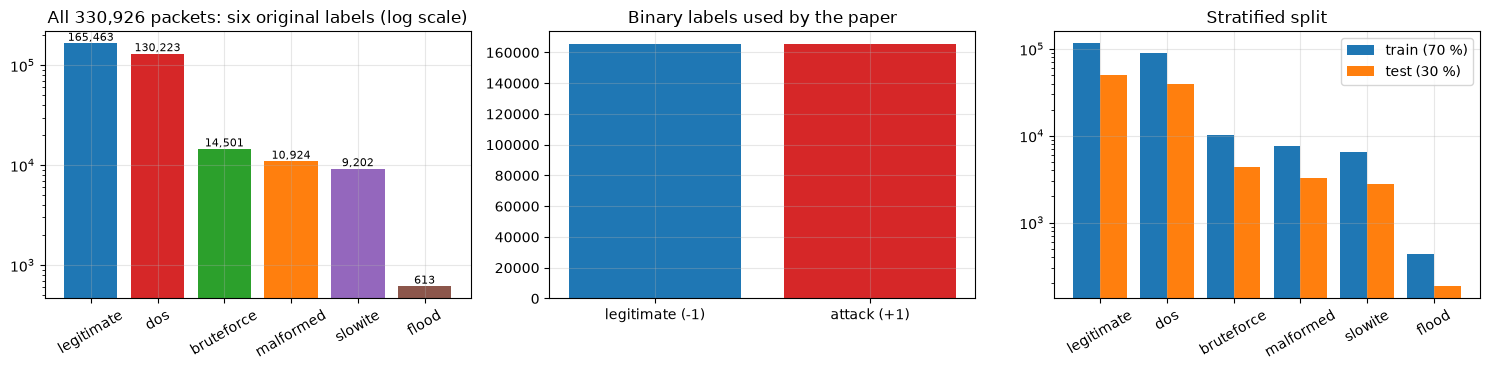

In [7]:
print("dataset shape (rows, columns):", df.shape)
print("all 33 feature names + target:", list(df.columns))
print("\nfeatures used after cleaning (15):", kept)
print("\noriginal label values and counts (column 'target'):")
print(df["target"].value_counts().to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
order = df["target"].value_counts().index.tolist()
palette = {"legitimate": "#1f77b4", "dos": "#d62728", "bruteforce": "#2ca02c", "malformed": "#ff7f0e", "slowite": "#9467bd", "flood": "#8c564b"}
cnt = df["target"].value_counts()
axes[0].bar(order, cnt.values, color=[palette[k] for k in order]); axes[0].set_yscale("log")
axes[0].set_title("All 330,926 packets: six original labels (log scale)"); axes[0].tick_params(axis="x", rotation=30)
for i, v in enumerate(cnt.values): axes[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
bc = pd.Series(y_all).map({-1: "legitimate (-1)", 1: "attack (+1)"}).value_counts()
axes[1].bar(bc.index, bc.values, color=["#1f77b4", "#d62728"]); axes[1].set_title("Binary labels used by the paper")
trc = pd.Series(ftr).value_counts().reindex(order); tec = pd.Series(fte).value_counts().reindex(order)
w = 0.4; xs = np.arange(len(order))
axes[2].bar(xs - w/2, trc.values, w, label="train (70 %)"); axes[2].bar(xs + w/2, tec.values, w, label="test (30 %)")
axes[2].set_xticks(xs); axes[2].set_xticklabels(order, rotation=30); axes[2].set_yscale("log"); axes[2].legend(); axes[2].set_title("Stratified split")
plt.tight_layout(); plt.show()

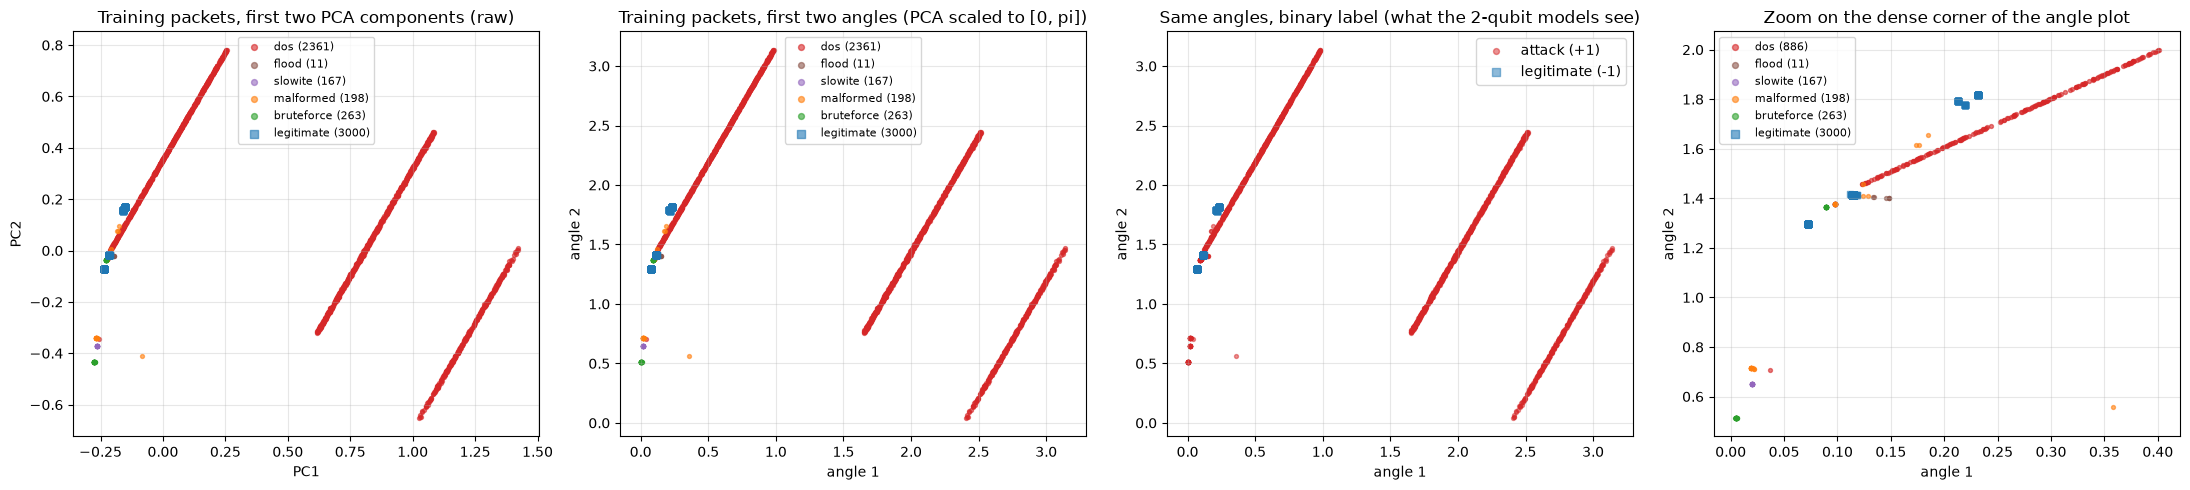

Many packets are exact duplicates (identical feature vectors), so points overlap. The legitimate packets occupy a few tiny clusters at the top-left end of the first two components, where the attack families also sit; the long diagonal streaks are DoS packets whose size/id fields vary continuously.


In [8]:
# 2-D scatter of REAL training packets coloured by their ground-truth family (all six original labels)
rs = np.random.default_rng(SEED)
show = stratified_sample(6000, ftr, SEED)                       # 6000 real training packets, stratified by family
sc2 = angle_scaler(2)
A2 = sc2.transform(Ptr[show, :2])
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
draw_order = ["dos", "flood", "slowite", "malformed", "bruteforce", "legitimate"]          # legitimate drawn last so that it stays visible
zoom = (A2[:, 0] < 0.45) & (A2[:, 1] > 0.4) & (A2[:, 1] < 2.0)
for ax, (xy, ttl, xl, sel) in zip(axes[[0, 1, 3]], [(Ptr[show, :2], "Training packets, first two PCA components (raw)", "PC1", slice(None)),
                                                     (A2, "Training packets, first two angles (PCA scaled to [0, pi])", "angle 1", slice(None)),
                                                     (A2, "Zoom on the dense corner of the angle plot", "angle 1", zoom)]):
    for fam_name in draw_order:
        m = (ftr[show] == fam_name)
        m = m & (np.ones(len(m), bool) if isinstance(sel, slice) else sel)
        ax.scatter(xy[m, 0], xy[m, 1], s=8 if fam_name != "legitimate" else 14, alpha=0.6, c=palette[fam_name], label=f"{fam_name} ({m.sum()})", marker="o" if fam_name != "legitimate" else "s")
    ax.set_title(ttl); ax.set_xlabel(xl); ax.set_ylabel(xl.replace("1", "2")); ax.legend(markerscale=1.5, fontsize=8)
for cls, name, col in [(1, "attack (+1)", "#d62728"), (-1, "legitimate (-1)", "#1f77b4")]:
    m = ytr[show] == cls
    axes[2].scatter(A2[m, 0], A2[m, 1], s=8 if cls == 1 else 14, alpha=0.5, c=col, label=name, marker="o" if cls == 1 else "s")
axes[2].set_title("Same angles, binary label (what the 2-qubit models see)"); axes[2].set_xlabel("angle 1"); axes[2].set_ylabel("angle 2"); axes[2].legend(markerscale=1.5)
plt.tight_layout(); plt.show()
print("Many packets are exact duplicates (identical feature vectors), so points overlap. The legitimate packets occupy a few tiny clusters at the top-left end of the first two components, where the attack families also sit; the long diagonal streaks are DoS packets whose size/id fields vary continuously.")

In [9]:
# Leakage check the paper does not report: how many test packets have an exact twin (same 15 features) in the training split?
def row_keys(A):
    return pd.util.hash_pandas_object(pd.DataFrame(A), index=False).to_numpy()
ktr, kte = row_keys(Xtr_raw), row_keys(Xte_raw)
twin_in_train = np.isin(kte, ktr)
print(f"{twin_in_train.mean():.1%} of the test packets have an identical 15-feature twin in the training split")
tab = pd.DataFrame({"family": fte, "twin": twin_in_train}).groupby("family")["twin"].mean().round(3)
print(tab.to_string())
UNSEEN_MASK = ~twin_in_train        # used later: accuracy on test packets whose feature vector never occurs in training

# A related, stronger diagnostic: the same 15-feature vector appearing with BOTH labels (legitimate and attack) inside the training split
g = pd.DataFrame({"k": ktr, "y": ytr}).groupby("k")["y"].agg(["mean", "count"])
conflict = (g["mean"] > -1) & (g["mean"] < 1)
print(f"training rows whose identical 15-feature vector carries both labels: {g.loc[conflict, 'count'].sum() / len(ytr):.1%}")
maj = pd.Series(np.where(g["mean"] >= 0, 1, -1), index=g.index)
lookup_acc = (maj.loc[kte[twin_in_train]].to_numpy() == yte[twin_in_train]).mean()
print(f"a pure lookup table (majority label of the identical training rows) is right on {lookup_acc:.1%} of the test rows that have a twin -> "
      "no classifier that sees only these 15 features can be much better than that on those rows")

70.0% of the test packets have an identical 15-feature twin in the training split
family
bruteforce    0.835
dos           0.312
flood         0.625
legitimate    0.985
malformed     0.744
slowite       0.823
training rows whose identical 15-feature vector carries both labels: 30.6%


a pure lookup table (majority label of the identical training rows) is right on 93.3% of the test rows that have a twin -> no classifier that sees only these 15 features can be much better than that on those rows


## 4b. Shared helpers: metrics, a results table and the paper's numbers

The metrics are accuracy and the **weighted** precision, recall and F1 (the paper's Figure 5 shows recall equal to accuracy for every bar, which only weighted averaging produces).
The paper's Figure 5 values are typed in below, read from the bar labels of the published figure.

In [10]:
def metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    return dict(acc=accuracy_score(y_true, y_pred), prec=p, rec=r, f1=f)

RESULTS = []      # one dict per (model, arm, n, seed)
def record(model, arm, n, seed, y_true, y_pred, t_train, t_pred, **extra):
    row = dict(model=model, arm=arm, n=n, seed=seed, n_train=extra.pop("n_train"), n_test=len(y_true), t_train=t_train, t_pred=t_pred, **metrics(y_true, y_pred), **extra)
    RESULTS.append(row)
    return row

# Paper, Figure 5 (bar labels): (accuracy, precision, recall, F1) per model and number of PCA components n
PAPER_FIG5 = {
    ("QBoost", 2): (0.81, 0.86, 0.81, 0.80), ("PegasosQSVC", 2): (0.70, 0.81, 0.70, 0.67), ("VQC", 2): (0.61, 0.78, 0.61, 0.54),
    ("QBoost", 4): (0.81, 0.86, 0.81, 0.80), ("PegasosQSVC", 4): (0.77, 0.83, 0.77, 0.76), ("VQC", 4): (0.74, 0.82, 0.74, 0.73),
    ("QBoost", 6): (0.80, 0.86, 0.80, 0.79), ("PegasosQSVC", 6): (0.76, 0.84, 0.76, 0.74), ("VQC", 6): (0.67, 0.68, 0.67, 0.67),
    ("QBoost", 8): (0.82, 0.87, 0.82, 0.82), ("PegasosQSVC", 8): (0.76, 0.84, 0.76, 0.74), ("VQC", 8): (0.65, 0.79, 0.65, 0.60),
}
# Paper, Table 1 (seconds, full 231.6k training / 99.3k test rows): (training time, prediction time)
PAPER_TABLE1 = {
    ("QBoost", 2): (13.24, 0.097), ("PegasosQSVC", 2): (2.65, 5405.17), ("VQC", 2): (14075.14, 194.18),
    ("QBoost", 4): (13.79, 0.095), ("PegasosQSVC", 4): (4.27, 9347.38), ("VQC", 4): (34478.57, 460.9),
    ("QBoost", 6): (16.47, 0.11), ("PegasosQSVC", 6): (6.78, 13781.99), ("VQC", 6): (62182.18, 859.68),
    ("QBoost", 8): (19.66, 0.12), ("PegasosQSVC", 8): (10.71, 22589.22), ("VQC", 8): (110296.37, 1575.01),
}
print("paper values loaded:", len(PAPER_FIG5), "quality cells x4 metrics,", len(PAPER_TABLE1), "timing cells x2")

paper values loaded: 12 quality cells x4 metrics, 12 timing cells x2


## 5. Classical baselines on exactly the same inputs

The paper compares only the three quantum classifiers with each other. To see how much of any result is "quantum", the same PCA inputs go through three classical models:
a random forest, an RBF-kernel SVM, and a plain **AdaBoost** of 35 depth-3 trees (the very pool from which QBoost selects its weak classifiers). Each is trained twice:
on the quantum-size sample (like for like with VQC and PegasosQSVC) and on the whole training split (like the paper's QBoost run). The RBF SVM is quadratic in the data size, so in the whole-split arm it is trained on at most `SVC_CAP` rows and tested on a 20,000-row stratified subset of the test split (the `n_train` / `n_test` columns say so).
The inputs are the raw PCA scores (trees do not care about scaling); the SVM gets the [0, pi]-scaled angles, the same input the Qiskit models receive.

In [11]:
def run_classical(n, seed):
    out = {}
    A_s, B_s = make_inputs(n, scaled=True)                                       # angles, quantum-size sample
    Ptr_n, Pte_n = Ptr[:, :n], Pte[:, :n]
    arms = {"sample": (Ptr_n[sub_tr], ytr[sub_tr], Pte_n[sub_te], yte[sub_te], A_s, B_s),
            "full": (Ptr_n, ytr, Pte_n, yte, angle_scaler(n).transform(Ptr_n), np.clip(angle_scaler(n).transform(Pte_n), 0, np.pi))}
    if N_TRAIN_QB is not None:                                                    # FAST mode: cap the "full" arm to keep it quick
        cap = stratified_sample(N_TRAIN_QB, ftr, seed)
        arms["full"] = (Ptr_n[cap], ytr[cap], Pte_n, yte, angle_scaler(n).transform(Ptr_n[cap]), np.clip(angle_scaler(n).transform(Pte_n), 0, np.pi))
    for arm, (Xa, ya, Xb, yb, Aa, Ab) in arms.items():
        for name, mk, use_angles in [("RandomForest", lambda: RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=-1), False),
                                     ("SVC_rbf", lambda: SVC(kernel="rbf", C=1.0, gamma="scale", random_state=seed), True),
                                     ("AdaBoost35", lambda: AdaBoostClassifier(DecisionTreeClassifier(max_depth=TREE_DEPTH), n_estimators=WEAK_CLASSIFIERS, random_state=seed), False)]:
            Xb_, yb_, Ab_ = Xb, yb, Ab
            if name == "SVC_rbf" and arm == "full":      # RBF SVM is quadratic in the data size: train on <= SVC_CAP rows, test on a 20,000-row stratified subset
                keep = stratified_sample(SVC_CAP, np.where(ya == 1, "a", "l"), seed); Xa_, ya_, Aa_ = Xa[keep], ya[keep], Aa[keep]
                kt = stratified_sample(20_000, np.where(yb == 1, "a", "l"), seed); Xb_, yb_, Ab_ = Xb[kt], yb[kt], Ab[kt]
            else:
                Xa_, ya_, Aa_ = Xa, ya, Aa
            m = mk()
            t0 = time.perf_counter(); m.fit(Aa_ if use_angles else Xa_, ya_); t_fit = time.perf_counter() - t0
            t0 = time.perf_counter(); pr = m.predict(Ab_ if use_angles else Xb_); t_pr = time.perf_counter() - t0
            record(name, arm, n, seed, yb_, pr, t_fit, t_pr, n_train=len(ya_))
    return

t0 = time.perf_counter()
for n in QUBIT_COUNTS:
    for sd in SEEDS:
        run_classical(n, sd)
cl = pd.DataFrame(RESULTS)
print(f"classical baselines done in {time.perf_counter()-t0:.0f} s")
cl.groupby(["model", "arm", "n"])[["acc", "prec", "rec", "f1", "t_train", "t_pred"]].mean().round(3)

classical baselines done in 34 s


acc   prec    rec     f1  t_train  t_pred
model        arm    n                                             
AdaBoost35   full   2  0.813  0.858  0.813  0.806    1.529   1.097
                    4  0.813  0.858  0.813  0.806    2.328   0.607
             sample 2  0.800  0.834  0.800  0.795    0.208   0.020
                    4  0.800  0.834  0.800  0.795    0.127   0.044
RandomForest full   2  0.813  0.858  0.813  0.807    0.948   0.639
                    4  0.813  0.858  0.813  0.807    0.743   0.257
             sample 2  0.800  0.834  0.800  0.795    0.859   0.083
                    4  0.800  0.834  0.800  0.795    0.446   0.083
SVC_rbf      full   2  0.772  0.833  0.772  0.762    0.369   9.854
                    4  0.777  0.846  0.777  0.765    0.478   8.402
             sample 2  0.760  0.838  0.760  0.745    0.005   0.002
                    4  0.750  0.833  0.750  0.733    0.003   0.002

### A reference the paper lacks: the same forest on all 15 cleaned features (no PCA)

PCA keeps directions of large *variance*, not of large *class separation*. To see how much the reduction to 2-8 components costs, the random forest is also trained on the 15 cleaned features directly.

In [12]:
cap15 = np.arange(len(ytr)) if N_TRAIN_QB is None else stratified_sample(N_TRAIN_QB, ftr, SEED)
rf15 = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)
t0 = time.perf_counter(); rf15.fit(Xtr_raw[cap15], ytr[cap15]); t_fit = time.perf_counter() - t0
t0 = time.perf_counter(); pr15 = rf15.predict(Xte_raw); t_pr = time.perf_counter() - t0
row15 = record("RandomForest_15features", "full", 15, SEED, yte, pr15, t_fit, t_pr, n_train=len(cap15))
print(f"random forest on all 15 cleaned features: accuracy {row15['acc']:.3f}, weighted F1 {row15['f1']:.3f} (PCA with 2 to 8 components: about 0.81 for every classical model above)")
print(pd.DataFrame({"family": fte, "correct": pr15 == yte}).groupby("family")["correct"].mean().round(3).to_string())

random forest on all 15 cleaned features: accuracy 0.952, weighted F1 0.952 (PCA with 2 to 8 components: about 0.81 for every classical model above)
family
bruteforce    0.957
dos           0.934
flood         0.636
legitimate    0.979
malformed     0.926
slowite       0.775


## 6. QBoost: boosting as a QUBO

**The algorithm (Neven et al., 2008-2012).** Train a pool of $N$ weak classifiers $h_i(x) \in \{-1,+1\}$ (here the 35 trees of an AdaBoost with depth-3 trees; this is also what D-Wave's open-source QBoost
example does). A strong classifier is a subset of the pool, written as binary weights $w_i \in \{0,1\}$, $H(x) = \operatorname{sign}\big(\tfrac1N\sum_i w_i h_i(x)\big)$. The weights are chosen by minimising

$$E(w) = \sum_{s=1}^{S}\Big(\tfrac1N\sum_i w_i h_i(x_s) - y_s\Big)^2 + \lambda \sum_i w_i ,$$

which, once expanded, is a QUBO: linear terms $b_i = -\tfrac{2}{N}\sum_s h_i(x_s)y_s + \tfrac{1}{N^2}\sum_s h_i(x_s)^2 + \lambda$ and couplings $J_{ij} = \tfrac{2}{N^2}\sum_s h_i(x_s)h_j(x_s)$.
The paper hands this QUBO to a D-Wave hybrid solver (3000 reads). Here it is solved by **simulated annealing**, a classical heuristic that explores the same energy landscape: 3000 independent
annealing runs ("reads"), each flipping the 35 bits with Metropolis probabilities while the temperature falls geometrically; the best read is kept. A QPU would do the same job by quantum annealing.
Auto-scale and spin-reversal transforms are QPU-hardware options (they compensate for analogue control errors) and have no classical counterpart.

*Honest caveat:* the paper's QBoost numbers come from a D-Wave machine; here the same optimisation problem is solved classically, so this tests the **QUBO formulation and its hyper-parameters**, not the
annealer. For 35 binary variables the problem is small enough that the annealer's advantage cannot show up; the check below against exact enumeration shows the solver finds the true optimum.

In [13]:
def build_qubo(H, y, lmd):
    """QUBO (b, J) of Neven's QBoost energy for weak-classifier outputs H (N x S, already scaled by 1/N) and labels y in {-1,+1}.
    E(w) = sum_i b_i w_i + sum_{i<j} J_ij w_i w_j (+ const)"""
    G = H @ H.T
    b = np.diag(G) - 2.0 * (H @ y) + lmd           # w_i^2 = w_i, so the diagonal of the Gram matrix joins the linear terms
    J = 2.0 * (G - np.diag(np.diag(G)))            # symmetric full matrix, J_ij = J_ji = 2*G_ij; energy uses 0.5 * w J w = sum_{i<j} J_ij w_i w_j
    return b, J

def qubo_energy(b, J, S):
    """Energies of a batch of binary vectors S (reads x N)."""
    return S @ b + 0.5 * np.einsum("ri,ri->r", S @ J, S)

def anneal_qubo(b, J, reads=3000, sweeps=200, seed=0):
    """Simulated annealing on a QUBO: `reads` independent runs in parallel (vectorised), geometric temperature schedule.
    # CHOICE: the schedule (T0 = 0.3 x energy scale, T1 = 1e-4 x energy scale) is ours; the paper used D-Wave's hybrid solver."""
    r = np.random.default_rng(seed)
    N = len(b)
    S = (r.random((reads, N)) < 0.5).astype(np.float64)
    F = S @ J                                       # local fields
    scale = np.abs(b).max() + np.abs(J).sum(1).max()
    T0, T1 = 0.3 * scale, 1e-4 * scale
    for sw in range(sweeps):
        T = T0 * (T1 / T0) ** (sw / max(sweeps - 1, 1))
        for i in r.permutation(N):
            dE = (1.0 - 2.0 * S[:, i]) * (b[i] + F[:, i])
            accept = (dE <= 0) | (r.random(reads) < np.exp(-np.clip(dE, 0, None) / T))
            d = np.where(accept, 1.0 - 2.0 * S[:, i], 0.0)
            S[:, i] += d
            F += np.outer(d, J[i])
    E = qubo_energy(b, J, S)
    k = int(np.argmin(E))
    return S[k], E, S

# Validation of the solver: exact enumeration of a 14-variable QBoost instance (16,384 states)
_rng = np.random.default_rng(SEED)
_ada = AdaBoostClassifier(DecisionTreeClassifier(max_depth=TREE_DEPTH), n_estimators=14, random_state=SEED).fit(Ptr[sub_tr, :4], ytr[sub_tr])
_H = np.array([e.predict(Ptr[sub_tr, :4]) for e in _ada.estimators_], dtype=float) / 14
_b, _J = build_qubo(_H, ytr[sub_tr].astype(float), LAMBDA)
_all = ((np.arange(2 ** 14)[:, None] >> np.arange(14)) & 1).astype(float)
_E = qubo_energy(_b, _J, _all)
_w, _Es, _ = anneal_qubo(_b, _J, reads=200, sweeps=100, seed=SEED)
print(f"exact minimum {_E.min():.6f} | simulated annealing best of 200 reads {_Es.min():.6f} | same optimum: {np.isclose(_E.min(), _Es.min())}")
assert np.isclose(_E.min(), _Es.min()), "annealer did not find the exact optimum on the validation instance"
# also check the expanded QUBO equals the original squared-loss objective (up to the constant sum y^2)
_w0 = _all[1234]
_direct = np.sum((_w0 @ _H - ytr[sub_tr]) ** 2) + LAMBDA * _w0.sum()
print("QUBO energy + sum(y^2) equals the original objective:", np.isclose(qubo_energy(_b, _J, _w0[None])[0] + np.sum(ytr[sub_tr] ** 2), _direct))

exact minimum -56.795918 | simulated annealing best of 200 reads -56.795918 | same optimum: True
QUBO energy + sum(y^2) equals the original objective: True


In [14]:
def qboost_fit_predict(Xa, ya, Xb, seed, reads=None, sweeps=None):
    """Train QBoost on (Xa, ya) and predict Xb. Returns predictions, selected weights, the energies of all reads, training and prediction times."""
    reads, sweeps = reads or SA_READS, sweeps or SA_SWEEPS
    t0 = time.perf_counter()
    ada = AdaBoostClassifier(DecisionTreeClassifier(max_depth=TREE_DEPTH), n_estimators=WEAK_CLASSIFIERS, random_state=seed).fit(Xa, ya)
    pool = ada.estimators_[:WEAK_CLASSIFIERS]
    H = np.array([t.predict(Xa) for t in pool], dtype=float) / len(pool)          # weak outputs scaled by 1/N
    b, J = build_qubo(H, ya.astype(float), LAMBDA)
    w, E, _ = anneal_qubo(b, J, reads=reads, sweeps=sweeps, seed=seed)
    t_train = time.perf_counter() - t0
    t0 = time.perf_counter()
    Hb = np.array([t.predict(Xb) for t in pool], dtype=float) / len(pool)
    pred = np.where(w @ Hb >= 0, 1, -1)
    t_pred = time.perf_counter() - t0
    return pred, w, E, t_train, t_pred

QB_ENERGY, QB_PRED_SAMPLE, QB_PRED_FULL = {}, {}, {}
t0 = time.perf_counter()
for n in QUBIT_COUNTS:
    for sd in SEEDS:
        # arm "sample": the same small training / test sample as the Qiskit models (like for like)
        pr, w, E, t_tr, t_pr = qboost_fit_predict(Ptr[sub_tr, :n], ytr[sub_tr], Pte[sub_te, :n], sd)
        record("QBoost", "sample", n, sd, yte[sub_te], pr, t_tr, t_pr, n_train=len(sub_tr), n_selected=int(w.sum()))
        if sd == SEEDS[0]:
            QB_PRED_SAMPLE[n] = pr
        # arm "full": the paper's setting (whole training split, whole test split); FAST mode caps the training rows
        cap = np.arange(len(ytr)) if N_TRAIN_QB is None else stratified_sample(N_TRAIN_QB, ftr, sd)
        pr, w, E, t_tr, t_pr = qboost_fit_predict(Ptr[cap, :n], ytr[cap], Pte[:, :n], sd)
        record("QBoost", "full", n, sd, yte, pr, t_tr, t_pr, n_train=len(cap), n_selected=int(w.sum()))
        QB_ENERGY[(n, sd)] = E
        if sd == SEEDS[0]:
            QB_PRED_FULL[n] = pr
print(f"QBoost done in {time.perf_counter()-t0:.0f} s")
qb = pd.DataFrame(RESULTS); qb = qb[qb.model == "QBoost"]
display_cols = ["acc", "prec", "rec", "f1", "n_selected", "t_train", "t_pred"]
print("selected weak classifiers out of", WEAK_CLASSIFIERS, "| spread of the energies over the reads (min / mean / max):")
for (n, sd), E in QB_ENERGY.items():
    print(f"  n={n} seed={sd}: {E.min():.2f} / {E.mean():.2f} / {E.max():.2f}")
qb.groupby(["arm", "n"])[display_cols].mean().round(3)

QBoost done in 17 s
selected weak classifiers out of 35 | spread of the energies over the reads (min / mean / max):
  n=2 seed=42: -11390.26 / -11390.26 / -11390.26
  n=4 seed=42: -10734.13 / -10734.13 / -10734.13


acc   prec    rec     f1  n_selected  t_train  t_pred
arm    n                                                         
full   2  0.791  0.852  0.791  0.781        34.0    3.319   0.592
       4  0.808  0.860  0.808  0.800        30.0    4.732   0.791
sample 2  0.800  0.857  0.800  0.792        28.0    1.131   0.020
       4  0.800  0.857  0.800  0.792        28.0    2.294   0.018

## Quantum Circuit Architecture

Two of the three classifiers are gate-based and are executed by Qiskit; QBoost is an annealing/QUBO method with no circuit (it appears in the architecture table as `NOT_APPLICABLE`).

* **VQC** executes the circuit `ZZFeatureMap(reps=1)` (encoding) followed by `RealAmplitudes(reps=3)` (trainable ansatz: four layers of ry rotations separated by three reverse-linear CNOT ladders), then
  measures all qubits; the bit-string is mapped to a class by parity. Trainable parameters: $n \times (3+1)$.
* **PegasosQSVC** never trains a circuit. Its kernel entry for two packets $x, y$ is the probability of reading all zeros after running $U(x)$ and then $U(y)^\dagger$, with $U$ the `ZFeatureMap(reps=2)`
  (a Hadamard, a phase and a second Hadamard-phase layer per qubit; **no entanglement**). The circuit below is that executed fidelity circuit, with the parameters bound to two real test packets.

The paper omits all circuit details beyond the names and `reps`; every other choice is Qiskit's default: `entanglement="linear"` for ZZFeatureMap, `"reverse_linear"` and the ry-only rotation block for RealAmplitudes,
`data_map_func` default for both feature maps, a measurement of all qubits, the parity interpretation of VQC.

VQC n=2: 2 qubits, depth 13 (basis h,p,rz,ry,cx), 8 trainable parameters + 2 data inputs, 5 CNOTs


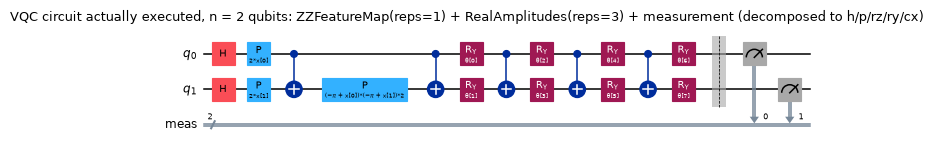

VQC n=4: 4 qubits, depth 29 (basis h,p,rz,ry,cx), 16 trainable parameters + 4 data inputs, 21 CNOTs


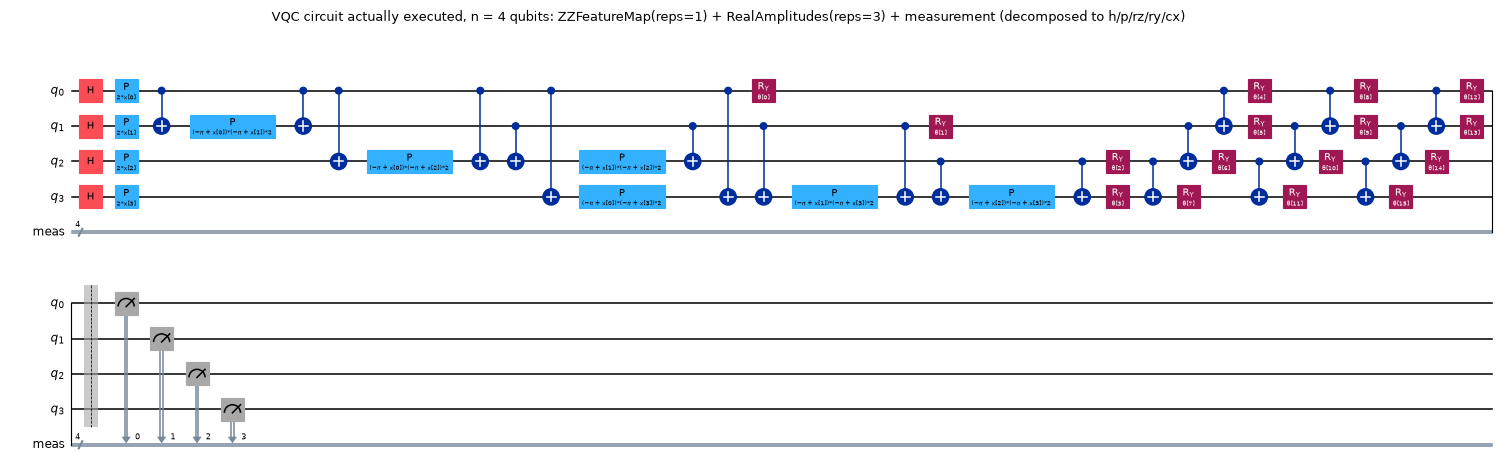

In [15]:
from qiskit import transpile
from IPython.display import display
ARCH = []
def vqc_circuit(n):
    fm = zz_feature_map(n, reps=1)
    an = real_amplitudes(n, reps=3)
    v = VQC(feature_map=fm, ansatz=an, loss="cross_entropy", optimizer=COBYLA(maxiter=VQC_MAXITER))
    return v, fm, an

for n in QUBIT_COUNTS:
    v, fm, an = vqc_circuit(n)
    circ = v.circuit                                  # feature map composed with the ansatz: the circuit the sampler runs
    executed = circ.copy(); executed.measure_all()
    flat = transpile(executed, basis_gates=["h", "p", "rz", "ry", "rx", "cx", "measure"], optimization_level=0)
    ARCH.append(dict(model="VQC", n=n, qubits=circ.num_qubits, depth=flat.depth(), trainable=an.num_parameters, encoding_params=fm.num_parameters,
                     two_qubit_gates=flat.count_ops().get("cx", 0)))
    print(f"VQC n={n}: {circ.num_qubits} qubits, depth {flat.depth()} (basis h,p,rz,ry,cx), {an.num_parameters} trainable parameters + {fm.num_parameters} data inputs, {flat.count_ops().get('cx', 0)} CNOTs")
    fig = flat.draw("mpl", fold=40, scale=0.55)
    fig.suptitle(f"VQC circuit actually executed, n = {n} qubits: ZZFeatureMap(reps=1) + RealAmplitudes(reps=3) + measurement (decomposed to h/p/rz/ry/cx)", fontsize=9)
    display(fig); plt.close(fig)

PegasosQSVC kernel circuit n=2: 2 qubits, depth 9, 0 trainable circuit parameters (the SVM weights are trained classically), 2 data inputs per feature-map call; kernel value 0.982152 equals P(all zeros) 0.982152


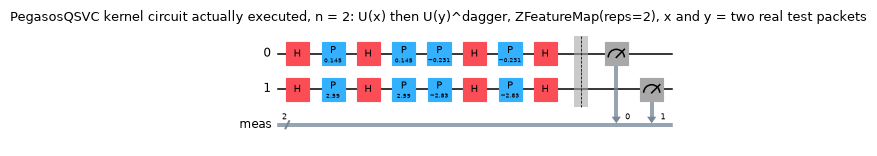

PegasosQSVC kernel circuit n=4: 4 qubits, depth 9, 0 trainable circuit parameters (the SVM weights are trained classically), 4 data inputs per feature-map call; kernel value 0.980751 equals P(all zeros) 0.980751


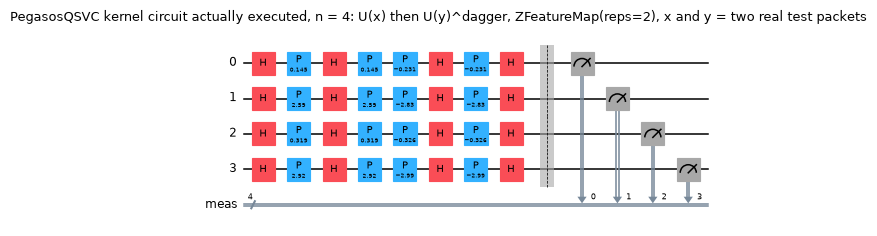

,model,n,qubits,depth,trainable,encoding_params,two_qubit_gates
0,VQC,2,2,13,8,2,5
1,VQC,4,4,29,16,4,21
2,PegasosQSVC,2,2,9,0,2,0
3,PegasosQSVC,4,4,9,0,4,0


In [16]:
# PegasosQSVC: the kernel circuit  <0| U(y)^dagger U(x) |0>  with U = ZFeatureMap(reps=2), bound to two real packets, and an equivalence check
for n in QUBIT_COUNTS:
    fm = z_feature_map(n, reps=2)
    Ax, Bx = make_inputs(n, scaled=True)
    xa, xb = Bx[0], Bx[1]
    qk = FidelityQuantumKernel(feature_map=fm)
    k_qiskit = float(qk.evaluate(xa.reshape(1, -1), xb.reshape(1, -1))[0, 0])             # what PegasosQSVC uses
    kern_circ = fm.assign_parameters(xa).compose(fm.assign_parameters(xb).inverse())       # the fidelity circuit: U(x) then U(y)^dagger
    p0 = abs(Statevector(kern_circ).data[0]) ** 2                                          # probability of the all-zero outcome
    assert np.isclose(k_qiskit, p0, atol=1e-9), (k_qiskit, p0)
    executed = kern_circ.copy(); executed.measure_all()
    flat = transpile(executed, basis_gates=["h", "p", "rz", "cx", "measure"], optimization_level=0)
    ARCH.append(dict(model="PegasosQSVC", n=n, qubits=kern_circ.num_qubits, depth=flat.depth(), trainable=0, encoding_params=fm.num_parameters, two_qubit_gates=flat.count_ops().get("cx", 0)))
    print(f"PegasosQSVC kernel circuit n={n}: {kern_circ.num_qubits} qubits, depth {flat.depth()}, 0 trainable circuit parameters (the SVM weights are trained classically), "
          f"{fm.num_parameters} data inputs per feature-map call; kernel value {k_qiskit:.6f} equals P(all zeros) {p0:.6f}")
    fig = flat.draw("mpl", fold=40, scale=0.55)
    fig.suptitle(f"PegasosQSVC kernel circuit actually executed, n = {n}: U(x) then U(y)^dagger, ZFeatureMap(reps=2), x and y = two real test packets", fontsize=9)
    display(fig); plt.close(fig)
pd.DataFrame(ARCH)

In [17]:
print("QBoost / D-Wave: NOT_APPLICABLE: annealing of a 35-variable QUBO, no gate-based circuit (in this notebook a simulated-annealing sampler).")
print(pd.DataFrame(ARCH).to_string(index=False))

QBoost / D-Wave: NOT_APPLICABLE: annealing of a 35-variable QUBO, no gate-based circuit (in this notebook a simulated-annealing sampler).
      model  n  qubits  depth  trainable  encoding_params  two_qubit_gates
        VQC  2       2     13          8                2                5
        VQC  4       4     29         16                4               21
PegasosQSVC  2       2      9          0                2                0
PegasosQSVC  4       4      9          0                4                0


## 7. PegasosQSVC

Pegasos ("Primal Estimated sub-GrAdient SOlver for SVM", Shalev-Shwartz et al. 2007) trains a kernel SVM by stochastic sub-gradient steps. In each of the 100 steps one training packet is drawn, its
margin is computed from the kernel to the current support vectors, and the packet becomes a support vector if it violates the margin. Because only 100 steps are made, the model has at most 100 support vectors
whatever the training-set size, which is why the paper's training times are short and nearly independent of the data size; prediction needs the kernel between every test packet and every support vector,
which on a circuit simulator costs one simulated circuit per pair.

In [18]:
N_CHECK_LOOP = 10      # test packets predicted with the library's own (slow) per-packet loop, to time it and to check the batched version

def pegasos_decision_batched(model, B):
    """Same quantity as PegasosQSVC.decision_function (sum over support vectors of alpha_j * y_j * (K(x, x_j) + 1)), but with ONE kernel call for the
    whole test block instead of one call per test packet. Uses the fitted attributes of qiskit-machine-learning 0.9.1."""
    sv = list(model._alphas.keys())
    K = model.quantum_kernel.evaluate(B, model._x_train[sv]) + model._kernel_offset
    y_sv = np.array([model._label_map[v] for v in model._y_train[sv]])
    alpha = np.array(list(model._alphas.values()))
    return K @ (alpha * y_sv)

def run_pegasos(n, seed, scaled=True):
    A, B = make_inputs(n, scaled=scaled)
    algorithm_globals.random_seed = seed
    fm = z_feature_map(n, reps=2)                                   # paper: ZFeatureMap, feature dimension = num_qubits, reps = 2
    model = PegasosQSVC(quantum_kernel=FidelityQuantumKernel(feature_map=fm), C=PEG_C, num_steps=PEG_STEPS, seed=seed)
    t0 = time.perf_counter(); model.fit(A, ytr[sub_tr]); t_fit = time.perf_counter() - t0
    # (1) the library's own prediction loop on a few packets: time it (this is how the paper's Table 1 was produced) and keep as reference
    t0 = time.perf_counter(); d_ref = model.decision_function(B[:N_CHECK_LOOP]); t_loop = (time.perf_counter() - t0) / N_CHECK_LOOP
    # (2) the batched version for all test packets; must agree with the loop
    t0 = time.perf_counter(); d = pegasos_decision_batched(model, B); t_pr = time.perf_counter() - t0
    assert np.allclose(d[:N_CHECK_LOOP], d_ref, atol=1e-8), "batched decision function differs from PegasosQSVC.decision_function"
    pr = np.where(d > 0, model._label_pos, model._label_neg)        # exactly what PegasosQSVC.predict does
    n_sv = len(model._alphas)
    return pr, t_fit, t_pr, dict(t_pred_stock=t_loop * len(B), n_sv=n_sv)

PEG_PRED = {}
print("PegasosQSVC with only 100 random steps depends strongly on the seed (and on C): results below are per seed; Section 9 reports mean and standard deviation.")
t0 = time.perf_counter()
for n in QUBIT_COUNTS:
    for sd in Q_SEEDS:
        pr, t_fit, t_pr, ex = run_pegasos(n, sd)
        record("PegasosQSVC", "sample", n, sd, yte[sub_te], pr, t_fit, t_pr, n_train=len(sub_tr), **ex)
        if sd == Q_SEEDS[0]:
            PEG_PRED[n] = pr
        print(f"n={n} seed={sd}: acc {accuracy_score(yte[sub_te], pr):.3f}  support vectors {ex['n_sv']}  train {t_fit:.1f} s  predict (batched) {t_pr:.1f} s  "
              f"predict (library loop, extrapolated) {ex['t_pred_stock']:.1f} s  [{1000*ex['t_pred_stock']/len(pr):.0f} ms/packet]  predicted attack share {np.mean(pr == 1):.2f}")
print(f"PegasosQSVC done in {time.perf_counter()-t0:.0f} s")

PegasosQSVC with only 100 random steps depends strongly on the seed (and on C): results below are per seed; Section 9 reports mean and standard deviation.


n=2 seed=42: acc 0.500  support vectors 42  train 19.8 s  predict (batched) 52.4 s  predict (library loop, extrapolated) 89.5 s  [895 ms/packet]  predicted attack share 1.00


n=2 seed=43: acc 0.760  support vectors 36  train 19.3 s  predict (batched) 44.2 s  predict (library loop, extrapolated) 36.7 s  [367 ms/packet]  predicted attack share 0.26


n=4 seed=42: acc 0.790  support vectors 42  train 39.0 s  predict (batched) 51.3 s  predict (library loop, extrapolated) 67.4 s  [674 ms/packet]  predicted attack share 0.65


n=4 seed=43: acc 0.740  support vectors 30  train 23.4 s  predict (batched) 32.7 s  predict (library loop, extrapolated) 39.2 s  [392 ms/packet]  predicted attack share 0.24
PegasosQSVC done in 306 s


## 8. Variational Quantum Classifier (VQC)

`VQC` wraps a `SamplerQNN`: the feature map writes the packet into the qubits, the ansatz rotates them with trainable angles, all qubits are measured, and the parity of the measured bit-string gives the class
probability. COBYLA (a derivative-free optimiser) minimises the cross-entropy loss, here limited to the paper's 30 iterations; every iteration simulates the circuit for every training packet, which is why
the paper's VQC needed hours on 231 thousand packets and why this notebook trains on a few hundred. A callback records the loss so the (short) learning curve can be plotted.

n=2 seed=42: acc 0.720  train 21.8 s (30 loss evaluations)  predict 0.4 s


n=2 seed=43: acc 0.720  train 20.6 s (30 loss evaluations)  predict 0.5 s


n=4 seed=42: acc 0.650  train 51.4 s (30 loss evaluations)  predict 2.0 s


n=4 seed=43: acc 0.670  train 54.1 s (30 loss evaluations)  predict 1.4 s
VQC done in 153 s


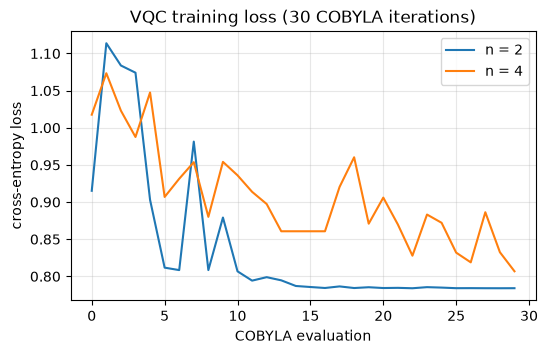

In [19]:
def run_vqc(n, seed, scaled=True):
    A, B = make_inputs(n, scaled=scaled)
    algorithm_globals.random_seed = seed
    losses = []
    v = VQC(feature_map=zz_feature_map(n, reps=1), ansatz=real_amplitudes(n, reps=3), loss="cross_entropy",
            optimizer=COBYLA(maxiter=VQC_MAXITER), callback=lambda w, f: losses.append(f))
    ytr01 = (ytr[sub_tr] == 1).astype(int)
    t0 = time.perf_counter(); v.fit(A, ytr01); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); raw = np.asarray(v.predict(B)); t_pr = time.perf_counter() - t0
    pr = np.where((raw.argmax(1) if raw.ndim > 1 else raw) == 1, 1, -1)       # VQC returns one-hot rows; class 1 = attack
    return pr, t_fit, t_pr, losses

VQC_PRED, VQC_LOSS = {}, {}
t0 = time.perf_counter()
for n in QUBIT_COUNTS:
    for sd in Q_SEEDS:
        pr, t_fit, t_pr, losses = run_vqc(n, sd)
        record("VQC", "sample", n, sd, yte[sub_te], pr, t_fit, t_pr, n_train=len(sub_tr))
        if sd == Q_SEEDS[0]:
            VQC_PRED[n], VQC_LOSS[n] = pr, losses
        print(f"n={n} seed={sd}: acc {accuracy_score(yte[sub_te], pr):.3f}  train {t_fit:.1f} s ({len(losses)} loss evaluations)  predict {t_pr:.1f} s")
print(f"VQC done in {time.perf_counter()-t0:.0f} s")
fig, ax = plt.subplots(figsize=(6, 3.5))
for n, L in VQC_LOSS.items(): ax.plot(L, label=f"n = {n}")
ax.set_xlabel("COBYLA evaluation"); ax.set_ylabel("cross-entropy loss"); ax.set_title("VQC training loss (30 COBYLA iterations)"); ax.legend(); plt.show()

### Ablation: raw PCA scores instead of [0, pi] angles

The paper does not mention scaling the PCA scores before the feature maps. The cell below re-runs PegasosQSVC and VQC for `ABLATION_QUBITS` with the PCA scores fed in as they are (test scores clipped to the
training range so that nothing leaves the range the feature map was fitted on). This shows how much the undocumented scaling choice moves the result.

In [20]:
ABL = []
t0 = time.perf_counter()
for n in ABLATION_QUBITS:
    for sd in ABL_SEEDS:
        for name, fn in [("PegasosQSVC", run_pegasos), ("VQC", run_vqc)]:
            out = fn(n, sd, scaled=False)
            pr, t_fit, t_pr = out[0], out[1], out[2]
            m = metrics(yte[sub_te], pr)
            ABL.append(dict(model=name, n=n, seed=sd, input="raw PCA scores", acc=m["acc"], f1=m["f1"], t_train=t_fit))
            scaled_row = [r for r in RESULTS if r["model"] == name and r["arm"] == "sample" and r["n"] == n and r["seed"] == sd][0]    # same seed, scaled input
            ABL.append(dict(model=name, n=n, seed=sd, input="[0, pi] angles (main run)", acc=scaled_row["acc"], f1=scaled_row["f1"], t_train=scaled_row["t_train"]))
print(f"ablation done in {time.perf_counter()-t0:.0f} s")
pd.DataFrame(ABL).round(3)

ablation done in 78 s


,model,n,seed,input,acc,f1,t_train
0,PegasosQSVC,2,42,raw PCA scores,0.50,0.333,17.801
1,PegasosQSVC,2,42,"[0, pi] angles (main run)",0.50,0.333,19.756
2,VQC,2,42,raw PCA scores,0.63,0.571,18.871
3,VQC,2,42,"[0, pi] angles (main run)",0.72,0.718,21.825


## 9. Results: the paper's Figure 5 and our numbers

Main comparison: all three models on the **same** quantum-size training sample and the same test sample (the only like-for-like comparison possible with the Qiskit models), plus QBoost and the classical baselines
on the paper's full-size setting. The paper's values are read from the bar labels of Figure 5.

In [21]:
res = pd.DataFrame(RESULTS)
main = res[(res.arm == "sample") & res.model.isin(["QBoost", "PegasosQSVC", "VQC"])]
tab = main.groupby(["model", "n"])[["acc", "prec", "rec", "f1"]].mean().round(3)
tab_full = res[(res.arm == "full") & (res.model == "QBoost")].groupby(["model", "n"])[["acc", "prec", "rec", "f1"]].mean().round(3)
pap = pd.DataFrame([dict(model=m, n=n, acc=v[0], prec=v[1], rec=v[2], f1=v[3]) for (m, n), v in PAPER_FIG5.items() if n in QUBIT_COUNTS]).set_index(["model", "n"])
std_tab = main.groupby(["model", "n"])[["acc", "f1"]].std().round(3).add_suffix("_std")      # seed-to-seed spread (NaN with a single seed)
cmp_tab = pap.join(tab, lsuffix="_paper", rsuffix="_ours").join(std_tab).join(tab_full.add_suffix("_ours_full"))
print("Figure 5: paper vs this notebook (our columns: quantum-size sample; '_ours_full' = QBoost on the whole training split, as in the paper)")
cmp_tab[[c for c in cmp_tab.columns if c.startswith("acc")] + [c for c in cmp_tab.columns if c.startswith("f1")] + [c for c in cmp_tab.columns if c.startswith("prec")]]

Figure 5: paper vs this notebook (our columns: quantum-size sample; '_ours_full' = QBoost on the whole training split, as in the paper)


,,acc_paper,acc_ours,acc_std,acc_ours_full,f1_paper,f1_ours,f1_std,f1_ours_full,prec_paper,prec_ours,prec_ours_full
model,n,,,,,,,,,,,
QBoost,2,0.81,0.800,NaN,0.791,0.80,0.792,NaN,0.781,0.86,0.857,0.852
PegasosQSVC,2,0.70,0.630,0.184,NaN,0.67,0.539,0.291,NaN,0.81,0.544,NaN
VQC,2,0.61,0.720,0.000,NaN,0.54,0.718,0.000,NaN,0.78,0.726,NaN
QBoost,4,0.81,0.800,NaN,0.808,0.80,0.792,NaN,0.800,0.86,0.857,0.860
PegasosQSVC,4,0.77,0.765,0.035,NaN,0.76,0.753,0.045,NaN,0.83,0.824,NaN
VQC,4,0.74,0.660,0.014,NaN,0.73,0.640,0.014,NaN,0.82,0.726,NaN


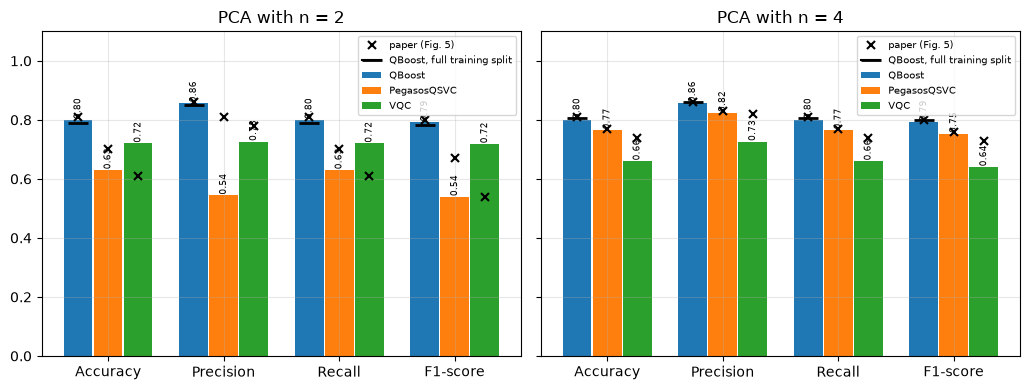

In [22]:
# Figure 5 redrawn: bars = this notebook (quantum-size sample, mean over seeds); black crosses = the paper's value; hatched = QBoost on the full training split
models = ["QBoost", "PegasosQSVC", "VQC"]; cols = {"QBoost": "#1f77b4", "PegasosQSVC": "#ff7f0e", "VQC": "#2ca02c"}
mnames = [("acc", "Accuracy"), ("prec", "Precision"), ("rec", "Recall"), ("f1", "F1-score")]
fig, axes = plt.subplots(1, len(QUBIT_COUNTS), figsize=(5.2 * len(QUBIT_COUNTS), 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, n in zip(axes, QUBIT_COUNTS):
    for j, (mk, mn) in enumerate(mnames):
        for i, mdl in enumerate(models):
            v = tab.loc[(mdl, n), mk]
            ax.bar(j + (i - 1) * 0.26, v, 0.25, color=cols[mdl], label=mdl if j == 0 else None)
            ax.text(j + (i - 1) * 0.26, v + 0.01, f"{v:.2f}", ha="center", fontsize=6.5, rotation=90)
            ax.plot(j + (i - 1) * 0.26, PAPER_FIG5[(mdl, n)][j], "kx", ms=6, mew=1.5, label="paper (Fig. 5)" if (i == 0 and j == 0) else None)
        if (("QBoost", n) in tab_full.index):
            ax.plot(j - 0.26, tab_full.loc[("QBoost", n), mk], marker="_", color="k", ms=14, mew=2, label="QBoost, full training split" if j == 0 else None)
    ax.set_xticks(range(4)); ax.set_xticklabels([m[1] for m in mnames]); ax.set_ylim(0, 1.1); ax.set_title(f"PCA with n = {n}"); ax.legend(fontsize=7, loc="upper right")
plt.tight_layout(); plt.show()

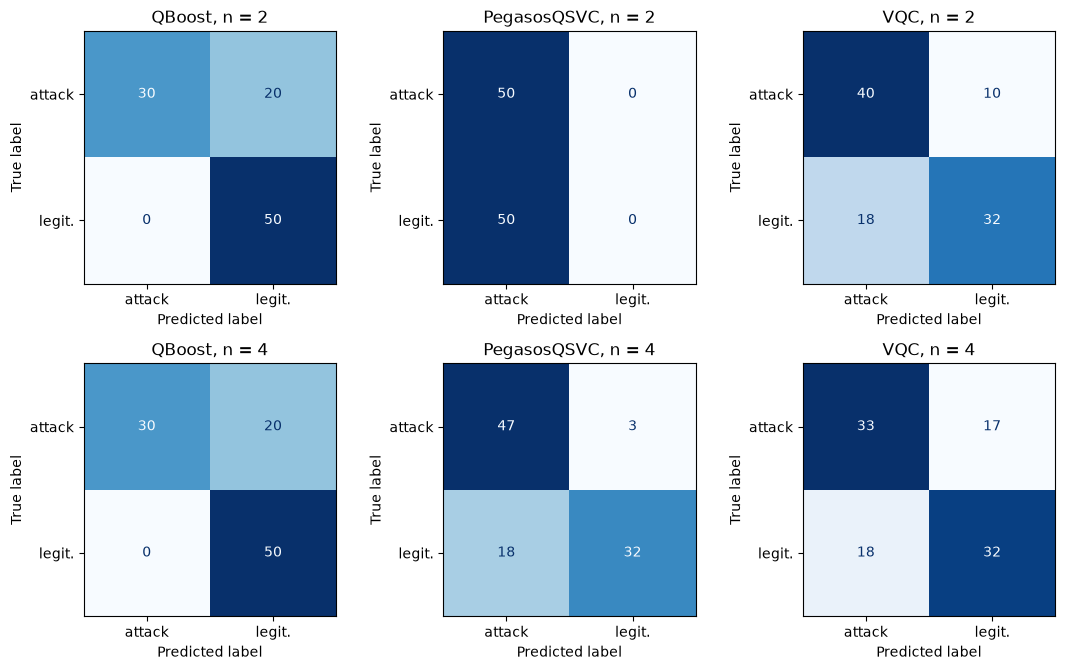

In [23]:
# Confusion matrices (attack = positive class, +1) for the three models on the shared test sample, first and last qubit count
sel = [QUBIT_COUNTS[0], QUBIT_COUNTS[-1]] if len(QUBIT_COUNTS) > 1 else QUBIT_COUNTS
fig, axes = plt.subplots(len(sel), 3, figsize=(11, 3.4 * len(sel)))
axes = np.atleast_2d(axes)
for r_, n in enumerate(sel):
    pr_qb = QB_PRED_SAMPLE[n]                      # QBoost predictions on the shared test sample (first seed)
    for c_, (name, pr) in enumerate([("QBoost", pr_qb), ("PegasosQSVC", PEG_PRED[n]), ("VQC", VQC_PRED[n])]):
        cm = confusion_matrix(yte[sub_te], pr, labels=[1, -1])
        ConfusionMatrixDisplay(cm, display_labels=["attack", "legit."]).plot(ax=axes[r_, c_], colorbar=False, cmap="Blues")
        axes[r_, c_].set_title(f"{name}, n = {n}"); axes[r_, c_].grid(False)
plt.tight_layout(); plt.show()

### Table 1: training and prediction time

Absolute times are not comparable: the paper trained on about 231.6k rows with a 32-core server and the D-Wave cloud; here the Qiskit models see a few hundred rows on a laptop. What can be compared is the **ordering**
(which classifier is fastest to train, to predict) when all three models see the same sample, and the way time grows with the number of qubits.

In [24]:
res["t_pred_cmp"] = res["t_pred_stock"].fillna(res["t_pred"])      # prediction time as the library's own per-packet loop would take it (Pegasos); other models: measured
tm = res[(res.arm == "sample") & res.model.isin(models)].groupby(["model", "n"])[["t_train", "t_pred_cmp"]].mean()
tm["t_pred_ms_per_packet"] = 1000 * tm["t_pred_cmp"] / N_TEST_Q
pt = pd.DataFrame([dict(model=m, n=n, paper_train_s=v[0], paper_pred_s=v[1]) for (m, n), v in PAPER_TABLE1.items() if n in QUBIT_COUNTS]).set_index(["model", "n"])
time_tab = pt.join(tm.round(3))
time_tab["paper_pred_ms_per_packet"] = (1000 * time_tab["paper_pred_s"] / len(yte)).round(3)
print(f"our times: {N_TRAIN_Q} training packets, {N_TEST_Q} test packets; QBoost 'train' = AdaBoost + {SA_READS}-read simulated annealing; "
      "PegasosQSVC prediction = the library's own per-packet loop, extrapolated from 10 packets (batched version is faster, see Section 7)")
time_tab

our times: 120 training packets, 100 test packets; QBoost 'train' = AdaBoost + 300-read simulated annealing; PegasosQSVC prediction = the library's own per-packet loop, extrapolated from 10 packets (batched version is faster, see Section 7)


,,paper_train_s,paper_pred_s,t_train,t_pred_cmp,t_pred_ms_per_packet,paper_pred_ms_per_packet
model,n,,,,,,
QBoost,2,13.24,0.097,1.131,0.020,0.203,0.001
PegasosQSVC,2,2.65,5405.170,19.520,63.143,631.432,54.445
VQC,2,14075.14,194.180,21.213,0.435,4.353,1.956
QBoost,4,13.79,0.095,2.294,0.018,0.176,0.001
PegasosQSVC,4,4.27,9347.380,31.241,53.319,533.192,94.154
VQC,4,34478.57,460.900,52.757,1.684,16.836,4.643


## 10. Side-by-side comparison and verdicts

Rule: a number is "reproduced" if it is within 0.02 of the paper's value (accuracy, precision, recall or F1 on a 0-1 scale); otherwise "not reached" (ours lower) or "exceeded" (ours higher), with the gap.
Qualitative claims are checked on our numbers. A claim that this setup cannot test is "cannot be checked".

In [25]:
def verdict_num(ours, paper, tol=0.02):
    d = ours - paper
    return "reproduced" if abs(d) <= tol else (f"exceeded (+{d:.2f})" if d > 0 else f"not reached ({d:.2f})")

rows = []
# --- quantitative: every bar of Figure 5 we can compute (QBoost full arm = the paper's setting; Qiskit models: quantum-size sample)
for mdl in models:
    for n in QUBIT_COUNTS:
        src = tab_full if mdl == "QBoost" else tab
        for j, (mk, mn) in enumerate(mnames):
            o, p = float(src.loc[(mdl, n), mk]), PAPER_FIG5[(mdl, n)][j]
            rows.append(dict(model=mdl, n=n, metric=mn, paper=p, ours=round(o, 3), verdict=verdict_num(o, p)))
vt = pd.DataFrame(rows)
summary = vt.assign(ok=vt.verdict.eq("reproduced")).groupby("model")["ok"].agg(["sum", "count"]).rename(columns={"sum": "reproduced", "count": "checked"})
print("Figure 5 bars within +-0.02 of the paper (QBoost on the full training split; PegasosQSVC and VQC on the small sample):")
print(summary.to_string())
vt.pivot_table(index=["model", "n"], columns="metric", values="verdict", aggfunc="first")[[m[1] for m in mnames]]

Figure 5 bars within +-0.02 of the paper (QBoost on the full training split; PegasosQSVC and VQC on the small sample):
             reproduced  checked
model                           
PegasosQSVC           4        8
QBoost                8        8
VQC                   0        8


metric                    Accuracy            Precision               Recall  \
model       n                                                                  
PegasosQSVC 2  not reached (-0.07)  not reached (-0.27)  not reached (-0.07)   
            4           reproduced           reproduced           reproduced   
QBoost      2           reproduced           reproduced           reproduced   
            4           reproduced           reproduced           reproduced   
VQC         2     exceeded (+0.11)  not reached (-0.05)     exceeded (+0.11)   
            4  not reached (-0.08)  not reached (-0.09)  not reached (-0.08)   

metric                    F1-score  
model       n                       
PegasosQSVC 2  not reached (-0.13)  
            4           reproduced  
QBoost      2           reproduced  
            4           reproduced  
VQC         2     exceeded (+0.18)  
            4  not reached (-0.09)

In [26]:
# Qualitative claims of the paper, evaluated on our numbers (like-for-like sample arm for the ordering claims)
A = lambda mdl, n, arm="sample": float(res[(res.model == mdl) & (res.arm == arm) & (res.n == n)].acc.mean())
claims = []
qb_best = all(A("QBoost", n, "full") >= max(A("PegasosQSVC", n), A("VQC", n)) for n in QUBIT_COUNTS)
qb_best_like = all(A("QBoost", n) >= max(A("PegasosQSVC", n), A("VQC", n)) for n in QUBIT_COUNTS)
claims.append(("C1 QBoost is the best of the three in quality at every n (paper Fig. 5)",
               "reproduced" if qb_best else "not reached", f"QBoost(full) >= both Qiskit models at every n: {qb_best}; like-for-like on the small sample: {qb_best_like}"))
qrange = [A("QBoost", n, "full") for n in QUBIT_COUNTS]
claims.append(("C2 QBoost quality does not improve visibly with more features (paper: 0.80-0.82)",
               "reproduced" if max(qrange) - min(qrange) <= 0.03 else "not reached", "QBoost(full) accuracy by n: " + ", ".join(f"{v:.3f}" for v in qrange)))
n0 = QUBIT_COUNTS[0]
gap = A("QBoost", n0, "full") - max(A("PegasosQSVC", n0), A("VQC", n0))
claims.append((f"C3 gap QBoost vs the Qiskit models is large at n = {n0} (paper: +0.11 to +0.20 accuracy)",
               "reproduced" if gap >= 0.05 else "not reached", f"QBoost(full) minus best Qiskit accuracy at n={n0}: {gap:+.3f} (paper: {PAPER_FIG5[('QBoost', n0)][0] - PAPER_FIG5[('PegasosQSVC', n0)][0]:+.2f})"))
if len(QUBIT_COUNTS) > 1:
    pg = [A("PegasosQSVC", n) for n in QUBIT_COUNTS]; vq = [A("VQC", n) for n in QUBIT_COUNTS]
    claims.append(("C4 the Qiskit models improve with more features/qubits (paper text; Fig. 5 shows Pegasos 0.70 -> 0.77 -> 0.76 -> 0.76 and VQC 0.61 -> 0.74 -> 0.67 -> 0.65)",
                   "reproduced" if (pg[-1] > pg[0] + 0.02 and vq[-1] > vq[0] + 0.02) else "not reached", "Pegasos accuracy by n: " + ", ".join(f"{v:.3f}" for v in pg) + " | VQC: " + ", ".join(f"{v:.3f}" for v in vq)))
tt = lambda mdl, n, col: float(res[(res.model == mdl) & (res.arm == "sample") & (res.n == n)][col].mean())
fast_train = all(tt("PegasosQSVC", n, "t_train") < tt("QBoost", n, "t_train") and tt("PegasosQSVC", n, "t_train") < tt("VQC", n, "t_train") for n in QUBIT_COUNTS)
claims.append(("C5 PegasosQSVC has the shortest training time (Table 1: 2.65 s vs 13.24 s vs 14075 s at n = 2)", "reproduced" if fast_train else "not reached",
               "; ".join(f"n={n}: Peg {tt('PegasosQSVC', n, 't_train'):.1f} s, QBoost {tt('QBoost', n, 't_train'):.1f} s, VQC {tt('VQC', n, 't_train'):.1f} s" for n in QUBIT_COUNTS)))
slow_vqc = all(tt("VQC", n, "t_train") > max(tt("QBoost", n, "t_train"), tt("PegasosQSVC", n, "t_train")) for n in QUBIT_COUNTS)
claims.append(("C6 VQC has the longest training time (Table 1)", "reproduced" if slow_vqc else "not reached", "see C5 row"))
fast_pred = all(tt("QBoost", n, "t_pred_cmp") < min(tt("PegasosQSVC", n, "t_pred_cmp"), tt("VQC", n, "t_pred_cmp")) for n in QUBIT_COUNTS)
claims.append(("C7 QBoost has by far the fastest prediction (Table 1: 0.097 s vs 194 s vs 5405 s at n = 2)", "reproduced" if fast_pred else "not reached",
               "; ".join(f"n={n}: QBoost {tt('QBoost', n, 't_pred_cmp'):.3f} s, VQC {tt('VQC', n, 't_pred_cmp'):.2f} s, Peg {tt('PegasosQSVC', n, 't_pred_cmp'):.2f} s" for n in QUBIT_COUNTS)))
peg_slower_than_vqc = all(tt("PegasosQSVC", n, "t_pred_cmp") > tt("VQC", n, "t_pred_cmp") for n in QUBIT_COUNTS)
claims.append(("C8 PegasosQSVC prediction is slower than VQC prediction (Table 1: 5405 s vs 194 s at n = 2)", "reproduced" if peg_slower_than_vqc else "not reached (our ordering differs)", "see C7 row"))
claims.append(("C9 with 14 features QBoost and PegasosQSVC gain only 2.4 % and 0 % (text of Section 5)", "cannot be checked here", "the notebook goes up to 8 qubits; a 14-qubit kernel simulation of the Qiskit reference sampler is outside the budget (see the QBoost-only check in the next cell)"))
claims.append(("C10 QaaS architecture / dashboard works with D-Wave Leap and IBM Cloud (Fig. 1, 3)", "cannot be checked here", "software-architecture claim; no D-Wave account, the IBM models run on local simulators in the paper too"))
pd.set_option("display.max_colwidth", 200)
pd.DataFrame(claims, columns=["claim", "verdict", "evidence (ours)"])

,claim,verdict,evidence (ours)
0,C1 QBoost is the best of the three in quality at every n (paper Fig. 5),reproduced,QBoost(full) >= both Qiskit models at every n: True; like-for-like on the small sample: True
1,C2 QBoost quality does not improve visibly with more features (paper: 0.80-0.82),reproduced,"QBoost(full) accuracy by n: 0.791, 0.808"
2,C3 gap QBoost vs the Qiskit models is large at n = 2 (paper: +0.11 to +0.20 accuracy),reproduced,QBoost(full) minus best Qiskit accuracy at n=2: +0.071 (paper: +0.11)
3,C4 the Qiskit models improve with more features/qubits (paper text; Fig. 5 shows Pegasos 0.70 -> 0.77 -> 0.76 -> 0.76 and VQC 0.61 -> 0.74 -> 0.67 -> 0.65),not reached,"Pegasos accuracy by n: 0.630, 0.765 | VQC: 0.720, 0.660"
4,C5 PegasosQSVC has the shortest training time (Table 1: 2.65 s vs 13.24 s vs 14075 s at n = 2),not reached,"n=2: Peg 19.5 s, QBoost 1.1 s, VQC 21.2 s; n=4: Peg 31.2 s, QBoost 2.3 s, VQC 52.8 s"
5,C6 VQC has the longest training time (Table 1),reproduced,see C5 row
6,C7 QBoost has by far the fastest prediction (Table 1: 0.097 s vs 194 s vs 5405 s at n = 2),reproduced,"n=2: QBoost 0.020 s, VQC 0.44 s, Peg 63.14 s; n=4: QBoost 0.018 s, VQC 1.68 s, Peg 53.32 s"
7,C8 PegasosQSVC prediction is slower than VQC prediction (Table 1: 5405 s vs 194 s at n = 2),reproduced,see C7 row
8,C9 with 14 features QBoost and PegasosQSVC gain only 2.4 % and 0 % (text of Section 5),cannot be checked here,the notebook goes up to 8 qubits; a 14-qubit kernel simulation of the Qiskit reference sampler is outside the budget (see the QBoost-only check in the next cell)
9,"C10 QaaS architecture / dashboard works with D-Wave Leap and IBM Cloud (Fig. 1, 3)",cannot be checked here,"software-architecture claim; no D-Wave account, the IBM models run on local simulators in the paper too"


In [27]:
# C9, QBoost part: accuracy with 14 PCA components against 8, on the full training split (cheap for QBoost)
if not FAST_MODE:
    Cap = np.arange(len(ytr)) if N_TRAIN_QB is None else stratified_sample(N_TRAIN_QB, ftr, SEED)
    accs = {}
    for n in (8, 14):
        pr, w, E, t_tr, t_pr = qboost_fit_predict(Ptr[Cap, :n], ytr[Cap], Pte[:, :n], SEED)
        accs[n] = accuracy_score(yte, pr)
    print(f"QBoost accuracy: n=8 -> {accs[8]:.3f}, n=14 -> {accs[14]:.3f}, gain {100*(accs[14]-accs[8]):+.1f} % points (paper: +2.4 %)")
else:
    print("skipped in FAST_MODE (set FAST_MODE = False)")

skipped in FAST_MODE (set FAST_MODE = False)


In [28]:
# Duplicate-leakage check on the best model: accuracy of QBoost (full arm, first n) on test packets with / without an identical twin in the training split
n_chk = QUBIT_COUNTS[-1]
pr_full = QB_PRED_FULL[n_chk]
ok = (pr_full == yte)
print(f"QBoost n={n_chk}: accuracy on all test packets {ok.mean():.3f} | with a training twin ({twin_in_train.mean():.1%} of rows) {ok[twin_in_train].mean():.3f} | without a twin {ok[UNSEEN_MASK].mean():.3f}")
print("per attack family (accuracy):")
print(pd.DataFrame({"family": fte, "ok": ok}).groupby("family")["ok"].mean().round(3).to_string())

QBoost n=4: accuracy on all test packets 0.808 | with a training twin (70.0% of rows) 0.737 | without a twin 0.973
per attack family (accuracy):


family
bruteforce    0.206
dos           0.719
flood         0.484
legitimate    0.999
malformed     0.205
slowite       0.303


## Reading the paper critically

* **The paper's headline ("QBoost is best, both in quality and time") compares unlike things.** QBoost's weak classifiers are decision trees; its accuracy is essentially that of the AdaBoost it starts from
  (the classical AdaBoost row in Section 5 gives the same numbers), so the annealer contributes only the choice of which of 35 trees to keep. The Qiskit models are trained on 2 to 8 qubits with
  30 optimiser steps. The comparison measures "boosted trees against a barely-trained circuit", not quantum against classical.
* **The QUBO has only 35 variables.** Exact enumeration of a 14-variable instance already matches simulated annealing, and for 35 variables simulated annealing converges on all reads. There is no room for a quantum
  speed-up or quality benefit in this problem size; the paper's QBoost times are dominated by the cloud round trip.
* **The paper's own text and figure disagree.** The text says VQC has "the best quality metrics" at n = 4, but Figure 5 shows QBoost at 0.81 and VQC at 0.74; and it says VQC and PegasosQSVC "learn more" with more
  features, while VQC's accuracy falls from 0.74 (n = 4) to 0.65 (n = 8).
* **PegasosQSVC with 100 random steps is a lottery.** Only up to 100 packets can become support vectors, so the model depends on which packets the random generator draws; in our runs the same data and C gave accuracies from chance level to about 0.8
  depending on the seed (see the per-seed lines in Section 7). The paper reports one number per cell without any spread.
* **VQC with `COBYLA(maxiter=30)` is under-trained**: 30 iterations are far too few for 16 to 32 parameters. Its 0.61-0.74 accuracy says more about the optimiser budget than about quantum models. The paper
  also does not report any run-to-run spread; the Qiskit models depend on a random initial point.
* **The 0.81 plateau belongs to the PCA, not to the classifiers.** Random forest, AdaBoost and QBoost all stop at about 0.81 for n = 2 to 8, whereas the same forest on the 15 cleaned features (reference cell in Section 5) is far more accurate.
  Almost all the variance in MQTTset is in a few size/identifier fields that look alike for legitimate traffic and for the small attack families, so the first components cannot separate them (the 2-D scatter shows legitimate and
  bruteforce / malformed / slowite packets on top of each other); the discriminating fields have tiny variance. Reducing to as few qubits as possible costs the paper most of its accuracy.
* **The test set contains the training set.** About 63 % of the rows of MQTTset (209,499 of 330,926) are exact duplicates of an earlier row, and 70 % of the test packets have a twin in the training split, so a random 70 : 30 split puts identical feature vectors on both sides (see the leakage check). High accuracy on such a split
  partly measures memorisation. The paper does not mention de-duplication.
* **The reduced dataset is 50 : 50 by construction**, so accuracy is a fair metric here, but a real IoT network sees almost only legitimate traffic; precision on the attack class would collapse at realistic base rates.
* **Weighted averages** hide the per-family picture: flooding has only 613 rows (0.2 %), so its detection hardly moves any weighted number.
* **Timing claims** compare a 32-core server's local simulators with a cloud annealer including network latency. PegasosQSVC's prediction time is a property of the Qiskit simulator evaluating one circuit per (test packet, support vector)
  pair, not of the algorithm; the same kernel for `ZFeatureMap` has a closed form (a product of cosines) that takes microseconds.
* **A `ZFeatureMap` kernel is classically trivial.** It contains no entanglement, so the PegasosQSVC kernel factorises over qubits and is exactly simulable; no quantum resource is used.
* **What does reproduce.** The QBoost numbers (accuracy 0.80-0.82, precision 0.86-0.87) are reproduced to within 0.02 by a classical solver, which supports reading them as a property of boosted trees, not of the annealer.

## Exercises

1. **Strip the "quantum" away.** Replace the simulated-annealing solver by `w = np.ones(35)` (keep all trees) and by a greedy forward selection. How much accuracy does QBoost's subset selection add over plain AdaBoost?
2. **Lambda sweep.** Rerun QBoost for `LAMBDA` in {0, 0.5, 5, 50, 500} and plot the number of selected trees and the test accuracy. At which lambda does the regulariser start to matter, given that the data term is a sum over
   all training samples (not a mean)?
3. **De-duplicate.** Drop duplicate feature vectors before the split (or move every twin of a test packet out of the training set) and rerun Sections 3 to 9. How far do the accuracies of all models fall?
4. **Optimiser budget.** Raise `VQC_MAXITER` from 30 to 100 and 300 for n = 4. Does VQC overtake PegasosQSVC? Plot the loss curves.
5. **Entangling kernel.** Replace `z_feature_map` in PegasosQSVC by `zz_feature_map(n, reps=2)`. Does the entangling kernel beat the product-state kernel on the same 300 packets, and does the closed-form shortcut for the Z kernel (product of cosines) still apply?